• Separate Boundary vs. Interior Spacing (h_boundary & h_interior): Seed outer polygon edges tightly (e.g., h_boundary = 0.25) while keeping the interior mesh coarser (e.g., h_interior = 0.65), or vice versa, and watch the mesh transition smoothly inward.

• Per-Edge Subdivision Override: Select any numbered edge (Edge 1, Edge 2, etc.) from a dropdown and set a custom number of divisions (or spacing) just for that single boundary segment—ideal for clamped edges or contact boundaries.

• Distance-Graded Interior Transition: When h_boundary is finer than h_interior, interior nodes smoothly grade outward from the dense boundary toward the coarser interior spacing.

Need to  be  refined  

In [2]:
import tkinter as tk
from tkinter import messagebox, ttk
import matplotlib.path as mpath
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
from matplotlib.collections import PolyCollection
from matplotlib.figure import Figure
import numpy as np
from scipy.spatial import Delaunay


# =========================================================
# 1. BOUNDARY-CONTROLLED BASE T3 MESHER
# =========================================================
def ensure_ccw(vertices):
    x, y = vertices[:, 0], vertices[:, 1]
    signed_area = 0.5 * np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y)
    return vertices[::-1] if signed_area < 0 else vertices


def point_to_segment_dist(pt, a, b):
    """Shortest Euclidean distance from point `pt` to line segment `ab`."""
    ab = b - a
    len_sq = np.dot(ab, ab)
    if len_sq < 1e-12:
        return np.linalg.norm(pt - a)
    t = np.clip(np.dot(pt - a, ab) / len_sq, 0.0, 1.0)
    proj = a + t * ab
    return np.linalg.norm(pt - proj)


def build_base_t3_boundary_control(
    raw_vertices,
    h_boundary,
    h_interior,
    edge_div_overrides,
    use_smoothing,
    iterations,
):
    """Generates a base T3 mesh with independent boundary and interior densities."""
    vertices = ensure_ccw(np.asarray(raw_vertices, dtype=float))
    num_edges = len(vertices)

    # Step 1: Seed Boundary Edges (using per-edge override or global h_boundary)
    boundary_nodes = []
    edge_spacings = []

    for i in range(num_edges):
        p_start = vertices[i]
        p_end = vertices[(i + 1) % num_edges]
        edge_len = np.linalg.norm(p_end - p_start)

        if i in edge_div_overrides and edge_div_overrides[i] is not None:
            n_div = max(1, int(edge_div_overrides[i]))
        else:
            n_div = max(1, int(np.round(edge_len / h_boundary)))

        edge_spacings.append(edge_len / n_div)
        for k in range(n_div):
            t = k / n_div
            boundary_nodes.append((1.0 - t) * p_start + t * p_end)

    boundary_nodes = np.array(boundary_nodes)
    min_b_spacing = min(edge_spacings) if edge_spacings else h_boundary

    # Step 2: Generate Smoothly Graded Interior Nodes
    poly_path = mpath.Path(vertices)
    xmin, ymin = vertices.min(axis=0)
    xmax, ymax = vertices.max(axis=0)

    # Use finest spacing as candidate grid step, then filter via distance grading
    h_step = min(min_b_spacing, h_interior)
    dy = h_step * np.sqrt(3) / 2.0

    accepted_nodes = list(boundary_nodes)
    row = 0
    y = ymin + dy
    transition_band = 2.5 * max(h_boundary, h_interior)

    while y < ymax:
        x_shift = (h_step / 2.0) if (row % 2 == 1) else 0.0
        x = xmin + (h_step / 2.0) + x_shift
        while x < xmax:
            pt = np.array([x, y])
            if poly_path.contains_point(pt):
                # Distance to nearest boundary edge
                dists = [
                    point_to_segment_dist(
                        pt, vertices[i], vertices[(i + 1) % num_edges]
                    )
                    for i in range(num_edges)
                ]
                d_wall = min(dists)

                # Smoothly blend from h_boundary near walls to h_interior inside
                alpha = np.clip(d_wall / transition_band, 0.0, 1.0)
                h_local = (1.0 - alpha) * min_b_spacing + alpha * h_interior

                existing = np.array(accepted_nodes)
                min_dist = np.min(np.linalg.norm(existing - pt, axis=1))
                if min_dist >= 0.78 * h_local:
                    accepted_nodes.append(pt)
            x += h_step
        y += dy
        row += 1

    nodes = np.array(accepted_nodes)
    num_b = len(boundary_nodes)

    # Step 3: Delaunay Triangulation + Polygon Clipping + CCW Check
    tri = Delaunay(nodes)
    valid_tris = []
    for simplex in tri.simplices:
        pts = nodes[simplex]
        if poly_path.contains_point(pts.mean(axis=0)):
            area2 = (pts[1, 0] - pts[0, 0]) * (pts[2, 1] - pts[0, 1]) - (
                pts[2, 0] - pts[0, 0]
            ) * (pts[1, 1] - pts[0, 1])
            if area2 > 1e-12:
                valid_tris.append(simplex)
            elif area2 < -1e-12:
                valid_tris.append([simplex[0], simplex[2], simplex[1]])
    tris = np.array(valid_tris, dtype=int)

    # Step 4: Laplacian Smoothing (Boundary Nodes Fixed!)
    if use_smoothing and len(nodes) > num_b and len(tris) > 0:
        nodes = apply_laplacian_smoothing(
            nodes, tris, set(range(num_b)), iterations
        )

    return nodes, tris, num_b


def apply_laplacian_smoothing(nodes, elements, fixed_node_ids, iterations):
    smoothed = nodes.copy()
    neighbors = {i: set() for i in range(len(smoothed))}
    for el in elements:
        k = len(el)
        for i in range(k):
            neighbors[el[i]].update([el[(i - 1) % k], el[(i + 1) % k]])

    for _ in range(iterations):
        new_pos = smoothed.copy()
        for idx in range(len(smoothed)):
            if idx not in fixed_node_ids and neighbors[idx]:
                nbrs = list(neighbors[idx])
                new_pos[idx] = 0.5 * smoothed[idx] + 0.5 * np.mean(
                    smoothed[nbrs], axis=0
                )
        smoothed = new_pos
    return smoothed


# =========================================================
# 2. HYBRID (Q4 + T3) & PURE Q4 CONVERTERS
# =========================================================
def merge_t3_to_hybrid_q4_t3(nodes, tris):
    edge_to_tris = {}
    for t_idx, tri in enumerate(tris):
        for i in range(3):
            edge = tuple(sorted((tri[i], tri[(i + 1) % 3])))
            edge_to_tris.setdefault(edge, []).append(t_idx)

    candidate_pairs = []
    for edge, adj_tris in edge_to_tris.items():
        if len(adj_tris) == 2:
            t1, t2 = adj_tris
            quad = form_ccw_quad(nodes, tris[t1], tris[t2], edge)
            if quad is not None:
                quality = quad_angle_quality(nodes[quad])
                if quality > 0.35:
                    candidate_pairs.append((quality, t1, t2, quad))

    candidate_pairs.sort(key=lambda x: x[0], reverse=True)
    used_tris = set()
    q4_elements = []
    for _, t1, t2, quad in candidate_pairs:
        if t1 not in used_tris and t2 not in used_tris:
            q4_elements.append(quad)
            used_tris.add(t1)
            used_tris.add(t2)

    t3_elements = [
        list(tris[i]) for i in range(len(tris)) if i not in used_tris
    ]
    return nodes, q4_elements, t3_elements


def form_ccw_quad(nodes, tri1, tri2, shared_edge):
    u, v = shared_edge
    opp1 = [n for n in tri1 if n not in shared_edge][0]
    opp2 = [n for n in tri2 if n not in shared_edge][0]
    quad = [u, opp1, v, opp2]
    pts = nodes[quad]

    crosses = []
    for i in range(4):
        v1 = pts[(i + 1) % 4] - pts[i]
        v2 = pts[(i + 2) % 4] - pts[(i + 1) % 4]
        crosses.append(v1[0] * v2[1] - v1[1] * v2[0])

    if all(c > 1e-12 for c in crosses):
        return quad
    if all(c < -1e-12 for c in crosses):
        return quad[::-1]
    return None


def quad_angle_quality(pts):
    max_dev = 0.0
    for k in range(4):
        v1 = pts[(k - 1) % 4] - pts[k]
        v2 = pts[(k + 1) % 4] - pts[k]
        cos_t = np.clip(
            np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2)),
            -1.0,
            1.0,
        )
        max_dev = max(max_dev, abs(90.0 - np.degrees(np.arccos(cos_t))))
    return max(0.0, 1.0 - max_dev / 90.0)


def subdivide_t3_to_pure_q4(nodes, tris, num_boundary_nodes):
    new_nodes = list(nodes)
    edge_midpoints = {}
    q4_elements = []
    boundary_midpoints = set()

    edge_counts = {}
    for tri in tris:
        for i in range(3):
            edge = tuple(sorted((tri[i], tri[(i + 1) % 3])))
            edge_counts[edge] = edge_counts.get(edge, 0) + 1

    def get_midpoint(u, v):
        edge = tuple(sorted((u, v)))
        if edge not in edge_midpoints:
            mid_pt = 0.5 * (nodes[u] + nodes[v])
            mid_idx = len(new_nodes)
            new_nodes.append(mid_pt)
            edge_midpoints[edge] = mid_idx
            if edge_counts[edge] == 1:
                boundary_midpoints.add(mid_idx)
        return edge_midpoints[edge]

    for n0, n1, n2 in tris:
        m01 = get_midpoint(n0, n1)
        m12 = get_midpoint(n1, n2)
        m20 = get_midpoint(n2, n0)
        c_idx = len(new_nodes)
        new_nodes.append((nodes[n0] + nodes[n1] + nodes[n2]) / 3.0)
        q4_elements.append([n0, m01, c_idx, m20])
        q4_elements.append([n1, m12, c_idx, m01])
        q4_elements.append([n2, m20, c_idx, m12])

    fixed_ids = set(range(num_boundary_nodes)) | boundary_midpoints
    return np.array(new_nodes), q4_elements, fixed_ids


# =========================================================
# 3. INTERACTIVE TKINTER BOUNDARY DENSITY REMESHER
# =========================================================
class BoundaryDensityRemesherApp:
    def __init__(self, root):
        self.root = root
        self.root.title('Interactive Remesher: Boundary & Interior Mesh Density')
        self.root.geometry('1040x710')

        self.clicked_pts = []
        self.polygon_closed = False
        self.edge_overrides = {}  # {edge_index: custom_num_divisions}

        # --- Left Sidebar ---
        panel = ttk.Frame(root, padding=14)
        panel.pack(side=tk.LEFT, fill=tk.Y)

        # 1. Element Type
        ttk.Label(
            panel, text='1. Element Type', font=('Arial', 11, 'bold')
        ).pack(anchor=tk.W, pady=(0, 4))
        self.mode_var = tk.StringVar(value='HYBRID')
        for label, val in [
            ('Hybrid Quad-Dominant (Q4 + T3)', 'HYBRID'),
            ('Pure All-Quad (Q4 Only)', 'PURE_Q4'),
            ('Triangle (T3 Only)', 'T3'),
        ]:
            ttk.Radiobutton(
                panel,
                text=label,
                variable=self.mode_var,
                value=val,
                command=self.remesh,
            ).pack(anchor=tk.W)

        ttk.Separator(panel, orient=tk.HORIZONTAL).pack(fill=tk.X, pady=6)

        # 2. Polygon Drawing
        ttk.Label(
            panel, text='2. Draw Polygon', font=('Arial', 11, 'bold')
        ).pack(anchor=tk.W, pady=(2, 4))
        ttk.Label(
            panel,
            text='• Left-Click: Add corners\n• Right-Click: Close & Mesh',
            justify=tk.LEFT,
        ).pack(anchor=tk.W, pady=(0, 6))

        btn_row = ttk.Frame(panel)
        btn_row.pack(fill=tk.X, pady=(0, 8))
        ttk.Button(
            btn_row, text='Close & Mesh', command=self.close_and_mesh
        ).pack(side=tk.LEFT, expand=True, fill=tk.X, padx=(0, 3))
        ttk.Button(
            btn_row, text='Clear All', command=self.clear_canvas
        ).pack(side=tk.RIGHT, expand=True, fill=tk.X, padx=(3, 0))

        ttk.Separator(panel, orient=tk.HORIZONTAL).pack(fill=tk.X, pady=6)

        # 3. Boundary Mesh Density
        ttk.Label(
            panel, text='3. Boundary Mesh Density', font=('Arial', 11, 'bold')
        ).pack(anchor=tk.W, pady=(2, 4))

        b_row = ttk.Frame(panel)
        b_row.pack(fill=tk.X)
        ttk.Label(b_row, text='Boundary Spacing (h_b):').pack(side=tk.LEFT)
        self.hb_var = tk.DoubleVar(value=0.35)
        ttk.Spinbox(
            b_row,
            from_=0.12,
            to=1.50,
            increment=0.05,
            textvariable=self.hb_var,
            width=6,
            command=self.remesh,
        ).pack(side=tk.RIGHT)

        ttk.Scale(
            panel,
            from_=0.12,
            to=1.20,
            variable=self.hb_var,
            command=self.on_slider_drag,
        ).pack(fill=tk.X, pady=(2, 8))

        # Per-Edge Subdivision Override
        ttk.Label(
            panel, text='Single Edge Override (Optional):', font=('Arial', 9, 'bold')
        ).pack(anchor=tk.W)
        edge_row = ttk.Frame(panel)
        edge_row.pack(fill=tk.X, pady=(2, 4))
        self.edge_select = ttk.Combobox(edge_row, state='readonly', width=10)
        self.edge_select.pack(side=tk.LEFT, padx=(0, 4))
        self.edge_select.bind('<<ComboboxSelected>>', self.on_edge_selected)

        ttk.Label(edge_row, text='Divs:').pack(side=tk.LEFT)
        self.edge_div_var = tk.IntVar(value=8)
        ttk.Spinbox(
            edge_row,
            from_=1,
            to=40,
            textvariable=self.edge_div_var,
            width=5,
        ).pack(side=tk.RIGHT)

        edge_btn_row = ttk.Frame(panel)
        edge_btn_row.pack(fill=tk.X, pady=(0, 8))
        ttk.Button(
            edge_btn_row, text='Apply Edge Divs', command=self.apply_edge_override
        ).pack(side=tk.LEFT, expand=True, fill=tk.X, padx=(0, 3))
        ttk.Button(
            edge_btn_row, text='Reset Edges', command=self.reset_edge_overrides
        ).pack(side=tk.RIGHT, expand=True, fill=tk.X, padx=(3, 0))

        ttk.Separator(panel, orient=tk.HORIZONTAL).pack(fill=tk.X, pady=6)

        # 4. Interior Mesh Density
        ttk.Label(
            panel, text='4. Interior Mesh Density', font=('Arial', 11, 'bold')
        ).pack(anchor=tk.W, pady=(2, 4))

        i_row = ttk.Frame(panel)
        i_row.pack(fill=tk.X)
        ttk.Label(i_row, text='Interior Spacing (h_i):').pack(side=tk.LEFT)
        self.hi_var = tk.DoubleVar(value=0.60)
        ttk.Spinbox(
            i_row,
            from_=0.15,
            to=1.50,
            increment=0.05,
            textvariable=self.hi_var,
            width=6,
            command=self.remesh,
        ).pack(side=tk.RIGHT)

        ttk.Scale(
            panel,
            from_=0.15,
            to=1.20,
            variable=self.hi_var,
            command=self.on_slider_drag,
        ).pack(fill=tk.X, pady=(2, 6))

        self.smooth_var = tk.BooleanVar(value=True)
        ttk.Checkbutton(
            panel,
            text='Laplacian Smoothing (10 passes)',
            variable=self.smooth_var,
            command=self.remesh,
        ).pack(anchor=tk.W, pady=(2, 4))

        self.show_edge_nums = tk.BooleanVar(value=True)
        ttk.Checkbutton(
            panel,
            text='Show Edge Numbers (E1, E2...)',
            variable=self.show_edge_nums,
            command=self.remesh,
        ).pack(anchor=tk.W, pady=(0, 6))

        ttk.Button(panel, text='Remesh Now', command=self.remesh).pack(
            fill=tk.X, pady=(0, 6)
        )

        ttk.Separator(panel, orient=tk.HORIZONTAL).pack(fill=tk.X, pady=6)

        # 5. Summary Report
        self.stats_label = ttk.Label(
            panel,
            text='Draw a closed polygon\nto adjust boundary density.',
            font=('Consolas', 10),
            justify=tk.LEFT,
        )
        self.stats_label.pack(anchor=tk.W)

        # --- Right Canvas ---
        plot_frame = ttk.Frame(root, padding=10)
        plot_frame.pack(side=tk.RIGHT, fill=tk.BOTH, expand=True)

        self.fig = Figure(figsize=(6, 6), dpi=100)
        self.ax = self.fig.add_subplot(111)
        self.canvas = FigureCanvasTkAgg(self.fig, master=plot_frame)
        self.canvas.get_tk_widget().pack(fill=tk.BOTH, expand=True)
        self.canvas.mpl_connect('button_press_event', self.on_canvas_click)

        self.redraw_drawing_state()

    def setup_axes(self, title):
        self.ax.clear()
        self.ax.set_xlim(0.0, 6.0)
        self.ax.set_ylim(0.0, 6.0)
        self.ax.set_aspect('equal', adjustable='box')
        self.ax.grid(True, linestyle='--', alpha=0.5)
        self.ax.set_xlabel('X')
        self.ax.set_ylabel('Y')
        self.ax.set_title(title)

    def on_canvas_click(self, event):
        if event.inaxes != self.ax or self.polygon_closed:
            return
        if event.button == 1:
            x_snap = round(event.xdata * 20) / 20.0
            y_snap = round(event.ydata * 20) / 20.0
            self.clicked_pts.append([x_snap, y_snap])
            self.redraw_drawing_state()
        elif event.button == 3:
            self.close_and_mesh()

    def redraw_drawing_state(self):
        self.setup_axes(
            f'Left-Click Corners ({len(self.clicked_pts)} placed) | Right-Click to Mesh'
        )
        if len(self.clicked_pts) > 0:
            pts = np.array(self.clicked_pts)
            self.ax.plot(pts[:, 0], pts[:, 1], 'k-o', lw=1.5, markersize=5)
            self.ax.plot(pts[0, 0], pts[0, 1], 'go', markersize=8)
        self.canvas.draw()

    def close_and_mesh(self):
        if len(self.clicked_pts) < 3:
            messagebox.showwarning(
                'Not Enough Points', 'Click at least 3 corners first.'
            )
            return
        self.polygon_closed = True
        self.edge_overrides = {}
        # Populate edge dropdown E1 .. En
        ccw_pts = ensure_ccw(np.asarray(self.clicked_pts, dtype=float))
        self.clicked_pts = ccw_pts.tolist()
        edge_labels = [f'Edge {i + 1}' for i in range(len(self.clicked_pts))]
        self.edge_select['values'] = edge_labels
        self.edge_select.current(0)
        self.remesh()

    def clear_canvas(self):
        self.clicked_pts = []
        self.polygon_closed = False
        self.edge_overrides = {}
        self.edge_select['values'] = []
        self.stats_label.config(
            text='Draw a closed polygon\nto adjust boundary density.'
        )
        self.redraw_drawing_state()

    def on_edge_selected(self, _event=None):
        idx = self.edge_select.current()
        if idx in self.edge_overrides:
            self.edge_div_var.set(self.edge_overrides[idx])

    def apply_edge_override(self):
        if not self.polygon_closed:
            return
        idx = self.edge_select.current()
        if idx >= 0:
            self.edge_overrides[idx] = int(self.edge_div_var.get())
            self.remesh()

    def reset_edge_overrides(self):
        self.edge_overrides = {}
        self.remesh()

    def on_slider_drag(self, _event=None):
        self.hb_var.set(round(self.hb_var.get(), 2))
        self.hi_var.set(round(self.hi_var.get(), 2))
        self.remesh()

    def remesh(self):
        if not self.polygon_closed:
            return

        hb = max(0.10, float(self.hb_var.get()))
        hi = max(0.12, float(self.hi_var.get()))
        use_smooth = self.smooth_var.get()
        mode = self.mode_var.get()

        nodes, tris, num_b = build_base_t3_boundary_control(
            self.clicked_pts,
            hb,
            hi,
            self.edge_overrides,
            use_smooth,
            iterations=10,
        )

        if mode == 'T3':
            q4_els, t3_els = [], [list(t) for t in tris]
        elif mode == 'HYBRID':
            nodes, q4_els, t3_els = merge_t3_to_hybrid_q4_t3(nodes, tris)
            if use_smooth:
                nodes = apply_laplacian_smoothing(
                    nodes, q4_els + t3_els, set(range(num_b)), 10
                )
        else:  # PURE_Q4
            nodes, q4_els, fixed_ids = subdivide_t3_to_pure_q4(
                nodes, tris, num_b
            )
            t3_els = []
            if use_smooth:
                nodes = apply_laplacian_smoothing(nodes, q4_els, fixed_ids, 10)

        total_els = len(q4_els) + len(t3_els)
        report = (
            f'Boundary h_b:     {hb:.2f}\n'
            f'Interior h_i:     {hi:.2f}\n'
            f'Edge Overrides:   {len(self.edge_overrides)}\n'
            f'-----------------------------\n'
            f'Boundary Nodes:   {num_b}\n'
            f'Total Nodes:      {len(nodes)}\n'
            f'Q4 Quads (Blue):  {len(q4_els)}\n'
            f'T3 Tris (Amber):  {len(t3_els)}\n'
            f'Total Elements:   {total_els}\n'
            f'Reissner-Mindlin: {len(nodes) * 3} DOFs'
        )
        self.stats_label.config(text=report)

        self.setup_axes(
            f'Boundary h_b={hb:.2f} | Interior h_i={hi:.2f} ({len(nodes)} Nodes)'
        )
        if q4_els:
            self.ax.add_collection(
                PolyCollection(
                    [nodes[el] for el in q4_els],
                    facecolors='#d6eaf8',
                    edgecolors='#1b4f72',
                    linewidths=0.85,
                )
            )
        if t3_els:
            self.ax.add_collection(
                PolyCollection(
                    [nodes[el] for el in t3_els],
                    facecolors='#fcf3cf',
                    edgecolors='#b7950b',
                    linewidths=0.85,
                )
            )

        # Plot interior nodes in red, boundary nodes in dark blue
        self.ax.plot(
            nodes[num_b:, 0],
            nodes[num_b:, 1],
            'ro',
            markersize=2.0,
            label='Interior Nodes',
        )
        self.ax.plot(
            nodes[:num_b, 0],
            nodes[:num_b, 1],
            'bo',
            markersize=3.2,
            label='Boundary Nodes',
        )

        # Label Edge 1, Edge 2, ... along boundary midpoints
        if self.show_edge_nums.get():
            pts = np.asarray(self.clicked_pts)
            n_pts = len(pts)
            for i in range(n_pts):
                mid = 0.5 * (pts[i] + pts[(i + 1) % n_pts])
                tag = f'E{i + 1}' + ('*' if i in self.edge_overrides else '')
                self.ax.text(
                    mid[0],
                    mid[1],
                    tag,
                    fontsize=9,
                    fontweight='bold',
                    color='darkred',
                    bbox=dict(
                        boxstyle='round,pad=0.15', fc='white', alpha=0.75, lw=0.5
                    ),
                )

        self.ax.legend(loc='upper right', fontsize=8)
        self.canvas.draw()


if __name__ == '__main__':
    root = tk.Tk()
    app = BoundaryDensityRemesherApp(root)
    root.mainloop()


In [4]:
import tkinter as tk
from tkinter import messagebox, ttk
import matplotlib.path as mpath
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
from matplotlib.collections import PolyCollection
from matplotlib.figure import Figure
import numpy as np
from scipy.spatial import Delaunay


# =========================================================
# 1. BASE T3 MESHER (Per-Edge Divisions + Uniform Interior)
# =========================================================
def ensure_ccw(vertices):
    x, y = vertices[:, 0], vertices[:, 1]
    signed_area = 0.5 * np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y)
    return vertices[::-1] if signed_area < 0 else vertices


def compute_edge_divisions(vertices, h_boundary, edge_div_overrides):
    """Returns the exact number of subdivisions for every polygon edge."""
    num_edges = len(vertices)
    divs = []
    for i in range(num_edges):
        if i in edge_div_overrides and edge_div_overrides[i] is not None:
            n_div = max(1, int(edge_div_overrides[i]))
        else:
            edge_len = np.linalg.norm(
                vertices[(i + 1) % num_edges] - vertices[i]
            )
            n_div = max(1, int(np.round(edge_len / h_boundary)))
        divs.append(n_div)
    return divs


def build_base_t3_edge_control(
    raw_vertices,
    h_boundary,
    h_interior,
    edge_div_overrides,
    use_smoothing,
    iterations,
):
    """Seeds boundary edges by exact division counts and interior uniformly by h_interior."""
    vertices = ensure_ccw(np.asarray(raw_vertices, dtype=float))
    num_edges = len(vertices)
    edge_divs = compute_edge_divisions(
        vertices, h_boundary, edge_div_overrides
    )

    # Step 1: Seed Boundary Nodes
    boundary_nodes = []
    for i in range(num_edges):
        p_start = vertices[i]
        p_end = vertices[(i + 1) % num_edges]
        n_div = edge_divs[i]
        for k in range(n_div):
            t = k / n_div
            boundary_nodes.append((1.0 - t) * p_start + t * p_end)
    boundary_nodes = np.array(boundary_nodes)

    # Step 2: Uniform Interior Node Seeding (No Distance Grading)
    poly_path = mpath.Path(vertices)
    xmin, ymin = vertices.min(axis=0)
    xmax, ymax = vertices.max(axis=0)
    dy = h_interior * np.sqrt(3) / 2.0

    interior_nodes = []
    row = 0
    y = ymin + dy
    while y < ymax:
        x_shift = (h_interior / 2.0) if (row % 2 == 1) else 0.0
        x = xmin + (h_interior / 2.0) + x_shift
        while x < xmax:
            pt = np.array([x, y])
            if poly_path.contains_point(pt):
                dist_to_b = np.min(
                    np.linalg.norm(boundary_nodes - pt, axis=1)
                )
                if dist_to_b > 0.50 * h_interior:
                    interior_nodes.append(pt)
            x += h_interior
        y += dy
        row += 1

    nodes = (
        np.vstack([boundary_nodes, np.array(interior_nodes)])
        if len(interior_nodes) > 0
        else boundary_nodes
    )
    num_b = len(boundary_nodes)

    # Step 3: Delaunay Triangulation + Polygon Clipping + CCW Ordering
    tri = Delaunay(nodes)
    valid_tris = []
    for simplex in tri.simplices:
        pts = nodes[simplex]
        if poly_path.contains_point(pts.mean(axis=0)):
            area2 = (pts[1, 0] - pts[0, 0]) * (pts[2, 1] - pts[0, 1]) - (
                pts[1, 1] - pts[0, 1]
            ) * (pts[2, 0] - pts[0, 0])
            if area2 > 1e-12:
                valid_tris.append(simplex)
            elif area2 < -1e-12:
                valid_tris.append([simplex[0], simplex[2], simplex[1]])
    tris = np.array(valid_tris, dtype=int)

    # Step 4: Optional Laplacian Smoothing (Boundary Nodes Stay Fixed)
    if use_smoothing and len(interior_nodes) > 0 and len(tris) > 0:
        nodes = apply_laplacian_smoothing(
            nodes, tris, set(range(num_b)), iterations
        )

    return nodes, tris, num_b, edge_divs


def apply_laplacian_smoothing(nodes, elements, fixed_node_ids, iterations):
    smoothed = nodes.copy()
    neighbors = {i: set() for i in range(len(smoothed))}
    for el in elements:
        k = len(el)
        for i in range(k):
            neighbors[el[i]].update([el[(i - 1) % k], el[(i + 1) % k]])

    for _ in range(iterations):
        new_pos = smoothed.copy()
        for idx in range(len(smoothed)):
            if idx not in fixed_node_ids and neighbors[idx]:
                nbrs = list(neighbors[idx])
                new_pos[idx] = 0.5 * smoothed[idx] + 0.5 * np.mean(
                    smoothed[nbrs], axis=0
                )
        smoothed = new_pos
    return smoothed


# =========================================================
# 2. HYBRID (Q4 + T3) & PURE Q4 CONVERTERS
# =========================================================
def merge_t3_to_hybrid_q4_t3(nodes, tris):
    edge_to_tris = {}
    for t_idx, tri in enumerate(tris):
        for i in range(3):
            edge = tuple(sorted((tri[i], tri[(i + 1) % 3])))
            edge_to_tris.setdefault(edge, []).append(t_idx)

    candidate_pairs = []
    for edge, adj_tris in edge_to_tris.items():
        if len(adj_tris) == 2:
            t1, t2 = adj_tris
            quad = form_ccw_quad(nodes, tris[t1], tris[t2], edge)
            if quad is not None:
                quality = quad_angle_quality(nodes[quad])
                if quality > 0.35:
                    candidate_pairs.append((quality, t1, t2, quad))

    candidate_pairs.sort(key=lambda x: x[0], reverse=True)
    used_tris = set()
    q4_elements = []
    for _, t1, t2, quad in candidate_pairs:
        if t1 not in used_tris and t2 not in used_tris:
            q4_elements.append(quad)
            used_tris.add(t1)
            used_tris.add(t2)

    t3_elements = [
        list(tris[i]) for i in range(len(tris)) if i not in used_tris
    ]
    return nodes, q4_elements, t3_elements


def form_ccw_quad(nodes, tri1, tri2, shared_edge):
    u, v = shared_edge
    opp1 = [n for n in tri1 if n not in shared_edge][0]
    opp2 = [n for n in tri2 if n not in shared_edge][0]
    quad = [u, opp1, v, opp2]
    pts = nodes[quad]

    crosses = []
    for i in range(4):
        v1 = pts[(i + 1) % 4] - pts[i]
        v2 = pts[(i + 2) % 4] - pts[(i + 1) % 4]
        crosses.append(v1[0] * v2[1] - v1[1] * v2[0])

    if all(c > 1e-12 for c in crosses):
        return quad
    if all(c < -1e-12 for c in crosses):
        return quad[::-1]
    return None


def quad_angle_quality(pts):
    max_dev = 0.0
    for k in range(4):
        v1 = pts[(k - 1) % 4] - pts[k]
        v2 = pts[(k + 1) % 4] - pts[k]
        cos_t = np.clip(
            np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2)),
            -1.0,
            1.0,
        )
        max_dev = max(max_dev, abs(90.0 - np.degrees(np.arccos(cos_t))))
    return max(0.0, 1.0 - max_dev / 90.0)


def subdivide_t3_to_pure_q4(nodes, tris, num_boundary_nodes):
    new_nodes = list(nodes)
    edge_midpoints = {}
    q4_elements = []
    boundary_midpoints = set()

    edge_counts = {}
    for tri in tris:
        for i in range(3):
            edge = tuple(sorted((tri[i], tri[(i + 1) % 3])))
            edge_counts[edge] = edge_counts.get(edge, 0) + 1

    def get_midpoint(u, v):
        edge = tuple(sorted((u, v)))
        if edge not in edge_midpoints:
            mid_pt = 0.5 * (nodes[u] + nodes[v])
            mid_idx = len(new_nodes)
            new_nodes.append(mid_pt)
            edge_midpoints[edge] = mid_idx
            if edge_counts[edge] == 1:
                boundary_midpoints.add(mid_idx)
        return edge_midpoints[edge]

    for n0, n1, n2 in tris:
        m01 = get_midpoint(n0, n1)
        m12 = get_midpoint(n1, n2)
        m20 = get_midpoint(n2, n0)
        c_idx = len(new_nodes)
        new_nodes.append((nodes[n0] + nodes[n1] + nodes[n2]) / 3.0)
        q4_elements.append([n0, m01, c_idx, m20])
        q4_elements.append([n1, m12, c_idx, m01])
        q4_elements.append([n2, m20, c_idx, m12])

    fixed_ids = set(range(num_boundary_nodes)) | boundary_midpoints
    return np.array(new_nodes), q4_elements, fixed_ids


# =========================================================
# 3. INTERACTIVE TKINTER PER-EDGE DIVISION REMESHER
# =========================================================
class PerEdgeDivisionRemesherApp:
    def __init__(self, root):
        self.root = root
        self.root.title('Interactive Remesher: Per-Edge Divisions & Uniform Interior')
        self.root.geometry('1050x710')

        self.clicked_pts = []
        self.polygon_closed = False
        self.edge_overrides = {}  # {edge_index: custom_num_divisions}
        self.current_edge_divs = []

        # --- Left Sidebar ---
        panel = ttk.Frame(root, padding=14)
        panel.pack(side=tk.LEFT, fill=tk.Y)

        # 1. Element Type
        ttk.Label(
            panel, text='1. Element Type', font=('Arial', 11, 'bold')
        ).pack(anchor=tk.W, pady=(0, 4))
        self.mode_var = tk.StringVar(value='HYBRID')
        for label, val in [
            ('Hybrid Quad-Dominant (Q4 + T3)', 'HYBRID'),
            ('Pure All-Quad (Q4 Only)', 'PURE_Q4'),
            ('Triangle (T3 Only)', 'T3'),
        ]:
            ttk.Radiobutton(
                panel,
                text=label,
                variable=self.mode_var,
                value=val,
                command=self.remesh,
            ).pack(anchor=tk.W)

        ttk.Separator(panel, orient=tk.HORIZONTAL).pack(fill=tk.X, pady=6)

        # 2. Polygon Drawing
        ttk.Label(
            panel, text='2. Draw Polygon', font=('Arial', 11, 'bold')
        ).pack(anchor=tk.W, pady=(2, 4))
        ttk.Label(
            panel,
            text='• Left-Click: Add corners\n• Right-Click: Close & Mesh',
            justify=tk.LEFT,
        ).pack(anchor=tk.W, pady=(0, 6))

        btn_row = ttk.Frame(panel)
        btn_row.pack(fill=tk.X, pady=(0, 8))
        ttk.Button(
            btn_row, text='Close & Mesh', command=self.close_and_mesh
        ).pack(side=tk.LEFT, expand=True, fill=tk.X, padx=(0, 3))
        ttk.Button(
            btn_row, text='Clear All', command=self.clear_canvas
        ).pack(side=tk.RIGHT, expand=True, fill=tk.X, padx=(3, 0))

        ttk.Separator(panel, orient=tk.HORIZONTAL).pack(fill=tk.X, pady=6)

        # 3. Boundary & Per-Edge Divisions
        ttk.Label(
            panel, text='3. Boundary Edge Divisions', font=('Arial', 11, 'bold')
        ).pack(anchor=tk.W, pady=(2, 4))

        b_row = ttk.Frame(panel)
        b_row.pack(fill=tk.X)
        ttk.Label(b_row, text='Default Boundary (h_b):').pack(side=tk.LEFT)
        self.hb_var = tk.DoubleVar(value=0.45)
        ttk.Spinbox(
            b_row,
            from_=0.12,
            to=1.50,
            increment=0.05,
            textvariable=self.hb_var,
            width=6,
            command=self.remesh,
        ).pack(side=tk.RIGHT)

        ttk.Scale(
            panel,
            from_=0.12,
            to=1.20,
            variable=self.hb_var,
            command=self.on_slider_drag,
        ).pack(fill=tk.X, pady=(2, 8))

        # Per-Edge Subdivision Override
        ttk.Label(
            panel, text='Per-Edge Subdivision Override:', font=('Arial', 9, 'bold')
        ).pack(anchor=tk.W)
        edge_row = ttk.Frame(panel)
        edge_row.pack(fill=tk.X, pady=(2, 4))
        self.edge_select = ttk.Combobox(edge_row, state='readonly', width=11)
        self.edge_select.pack(side=tk.LEFT, padx=(0, 4))
        self.edge_select.bind('<<ComboboxSelected>>', self.on_edge_selected)

        ttk.Label(edge_row, text='Divs:').pack(side=tk.LEFT)
        self.edge_div_var = tk.IntVar(value=6)
        ttk.Spinbox(
            edge_row,
            from_=1,
            to=50,
            textvariable=self.edge_div_var,
            width=5,
        ).pack(side=tk.RIGHT)

        edge_btn_row = ttk.Frame(panel)
        edge_btn_row.pack(fill=tk.X, pady=(0, 8))
        ttk.Button(
            edge_btn_row, text='Apply Edge Divs', command=self.apply_edge_override
        ).pack(side=tk.LEFT, expand=True, fill=tk.X, padx=(0, 3))
        ttk.Button(
            edge_btn_row, text='Reset Overrides', command=self.reset_edge_overrides
        ).pack(side=tk.RIGHT, expand=True, fill=tk.X, padx=(3, 0))

        ttk.Separator(panel, orient=tk.HORIZONTAL).pack(fill=tk.X, pady=6)

        # 4. Uniform Interior Mesh Density
        ttk.Label(
            panel, text='4. Uniform Interior Density', font=('Arial', 11, 'bold')
        ).pack(anchor=tk.W, pady=(2, 4))

        i_row = ttk.Frame(panel)
        i_row.pack(fill=tk.X)
        ttk.Label(i_row, text='Interior Spacing (h_i):').pack(side=tk.LEFT)
        self.hi_var = tk.DoubleVar(value=0.55)
        ttk.Spinbox(
            i_row,
            from_=0.15,
            to=1.50,
            increment=0.05,
            textvariable=self.hi_var,
            width=6,
            command=self.remesh,
        ).pack(side=tk.RIGHT)

        ttk.Scale(
            panel,
            from_=0.15,
            to=1.20,
            variable=self.hi_var,
            command=self.on_slider_drag,
        ).pack(fill=tk.X, pady=(2, 6))

        self.smooth_var = tk.BooleanVar(value=True)
        ttk.Checkbutton(
            panel,
            text='Laplacian Smoothing (10 passes)',
            variable=self.smooth_var,
            command=self.remesh,
        ).pack(anchor=tk.W, pady=(2, 4))

        self.show_edge_labels = tk.BooleanVar(value=True)
        ttk.Checkbutton(
            panel,
            text='Show Edge Divisions on Plot',
            variable=self.show_edge_labels,
            command=self.remesh,
        ).pack(anchor=tk.W, pady=(0, 6))

        ttk.Button(panel, text='Remesh Now', command=self.remesh).pack(
            fill=tk.X, pady=(0, 6)
        )

        ttk.Separator(panel, orient=tk.HORIZONTAL).pack(fill=tk.X, pady=6)

        # 5. Summary Report
        self.stats_label = ttk.Label(
            panel,
            text='Draw a closed polygon\nto set edge divisions.',
            font=('Consolas', 10),
            justify=tk.LEFT,
        )
        self.stats_label.pack(anchor=tk.W)

        # --- Right Canvas ---
        plot_frame = ttk.Frame(root, padding=10)
        plot_frame.pack(side=tk.RIGHT, fill=tk.BOTH, expand=True)

        self.fig = Figure(figsize=(6, 6), dpi=100)
        self.ax = self.fig.add_subplot(111)
        self.canvas = FigureCanvasTkAgg(self.fig, master=plot_frame)
        self.canvas.get_tk_widget().pack(fill=tk.BOTH, expand=True)
        self.canvas.mpl_connect('button_press_event', self.on_canvas_click)

        self.redraw_drawing_state()

    def setup_axes(self, title):
        self.ax.clear()
        self.ax.set_xlim(0.0, 6.0)
        self.ax.set_ylim(0.0, 6.0)
        self.ax.set_aspect('equal', adjustable='box')
        self.ax.grid(True, linestyle='--', alpha=0.5)
        self.ax.set_xlabel('X')
        self.ax.set_ylabel('Y')
        self.ax.set_title(title)

    def on_canvas_click(self, event):
        if event.inaxes != self.ax or self.polygon_closed:
            return
        if event.button == 1:
            x_snap = round(event.xdata * 20) / 20.0
            y_snap = round(event.ydata * 20) / 20.0
            self.clicked_pts.append([x_snap, y_snap])
            self.redraw_drawing_state()
        elif event.button == 3:
            self.close_and_mesh()

    def redraw_drawing_state(self):
        self.setup_axes(
            f'Left-Click Corners ({len(self.clicked_pts)} placed) | Right-Click to Mesh'
        )
        if len(self.clicked_pts) > 0:
            pts = np.array(self.clicked_pts)
            self.ax.plot(pts[:, 0], pts[:, 1], 'k-o', lw=1.5, markersize=5)
            self.ax.plot(pts[0, 0], pts[0, 1], 'go', markersize=8)
        self.canvas.draw()

    def close_and_mesh(self):
        if len(self.clicked_pts) < 3:
            messagebox.showwarning(
                'Not Enough Points', 'Click at least 3 corners first.'
            )
            return
        self.polygon_closed = True
        self.edge_overrides = {}
        ccw_pts = ensure_ccw(np.asarray(self.clicked_pts, dtype=float))
        self.clicked_pts = ccw_pts.tolist()

        edge_labels = [f'Edge {i + 1}' for i in range(len(self.clicked_pts))]
        self.edge_select['values'] = edge_labels
        self.edge_select.current(0)
        self.remesh()
        self.on_edge_selected()

    def clear_canvas(self):
        self.clicked_pts = []
        self.polygon_closed = False
        self.edge_overrides = {}
        self.current_edge_divs = []
        self.edge_select['values'] = []
        self.stats_label.config(
            text='Draw a closed polygon\nto set edge divisions.'
        )
        self.redraw_drawing_state()

    def on_edge_selected(self, _event=None):
        idx = self.edge_select.current()
        if idx >= 0 and idx < len(self.current_edge_divs):
            self.edge_div_var.set(self.current_edge_divs[idx])

    def apply_edge_override(self):
        if not self.polygon_closed:
            return
        idx = self.edge_select.current()
        if idx >= 0:
            self.edge_overrides[idx] = int(self.edge_div_var.get())
            self.remesh()

    def reset_edge_overrides(self):
        self.edge_overrides = {}
        self.remesh()
        self.on_edge_selected()

    def on_slider_drag(self, _event=None):
        self.hb_var.set(round(self.hb_var.get(), 2))
        self.hi_var.set(round(self.hi_var.get(), 2))
        self.remesh()
        self.on_edge_selected()

    def remesh(self):
        if not self.polygon_closed:
            return

        hb = max(0.10, float(self.hb_var.get()))
        hi = max(0.12, float(self.hi_var.get()))
        use_smooth = self.smooth_var.get()
        mode = self.mode_var.get()

        nodes, tris, num_b, edge_divs = build_base_t3_edge_control(
            self.clicked_pts,
            hb,
            hi,
            self.edge_overrides,
            use_smooth,
            iterations=10,
        )
        self.current_edge_divs = edge_divs

        if mode == 'T3':
            q4_els, t3_els = [], [list(t) for t in tris]
        elif mode == 'HYBRID':
            nodes, q4_els, t3_els = merge_t3_to_hybrid_q4_t3(nodes, tris)
            if use_smooth:
                nodes = apply_laplacian_smoothing(
                    nodes, q4_els + t3_els, set(range(num_b)), 10
                )
        else:  # PURE_Q4
            nodes, q4_els, fixed_ids = subdivide_t3_to_pure_q4(
                nodes, tris, num_b
            )
            t3_els = []
            if use_smooth:
                nodes = apply_laplacian_smoothing(nodes, q4_els, fixed_ids, 10)

        # In Pure Q4 mode, each boundary segment is split into 2 by midpoint subdivision
        display_divs = (
            [d * 2 for d in edge_divs] if mode == 'PURE_Q4' else edge_divs
        )
        display_num_b = num_b * 2 if mode == 'PURE_Q4' else num_b

        total_els = len(q4_els) + len(t3_els)
        report = (
            f'Default h_b:      {hb:.2f}\n'
            f'Interior h_i:     {hi:.2f}\n'
            f'Edge Overrides:   {len(self.edge_overrides)}\n'
            f'-----------------------------\n'
            f'Boundary Nodes:   {display_num_b}\n'
            f'Total Nodes:      {len(nodes)}\n'
            f'Q4 Quads (Blue):  {len(q4_els)}\n'
            f'T3 Tris (Amber):  {len(t3_els)}\n'
            f'Total Elements:   {total_els}\n'
            f'Reissner-Mindlin: {len(nodes) * 3} DOFs'
        )
        self.stats_label.config(text=report)

        self.setup_axes(
            f'Remeshed: {len(nodes)} Nodes ({len(q4_els)} Q4 + {len(t3_els)} T3)'
        )
        if q4_els:
            self.ax.add_collection(
                PolyCollection(
                    [nodes[el] for el in q4_els],
                    facecolors='#d6eaf8',
                    edgecolors='#1b4f72',
                    linewidths=0.85,
                )
            )
        if t3_els:
            self.ax.add_collection(
                PolyCollection(
                    [nodes[el] for el in t3_els],
                    facecolors='#fcf3cf',
                    edgecolors='#b7950b',
                    linewidths=0.85,
                )
            )

        # Plot interior nodes in red, boundary nodes in dark blue
        self.ax.plot(
            nodes[num_b:, 0],
            nodes[num_b:, 1],
            'ro',
            markersize=2.0,
            label='Interior Nodes',
        )
        self.ax.plot(
            nodes[:num_b, 0],
            nodes[:num_b, 1],
            'bo',
            markersize=3.2,
            label='Boundary Nodes',
        )

        # Show Edge ID + Number of Divisions on every boundary edge
        if self.show_edge_labels.get():
            pts = np.asarray(self.clicked_pts)
            n_pts = len(pts)
            for i in range(n_pts):
                mid = 0.5 * (pts[i] + pts[(i + 1) % n_pts])
                star = '*' if i in self.edge_overrides else ''
                tag = f'E{i + 1} ({display_divs[i]} div){star}'
                self.ax.text(
                    mid[0],
                    mid[1],
                    tag,
                    fontsize=8.5,
                    fontweight='bold',
                    color='darkred',
                    ha='center',
                    va='center',
                    bbox=dict(
                        boxstyle='round,pad=0.2', fc='white', alpha=0.85, lw=0.6
                    ),
                )

        self.ax.legend(loc='upper right', fontsize=8)
        self.canvas.draw()


if __name__ == '__main__':
    root = tk.Tk()
    app = PerEdgeDivisionRemesherApp(root)
    root.mainloop()


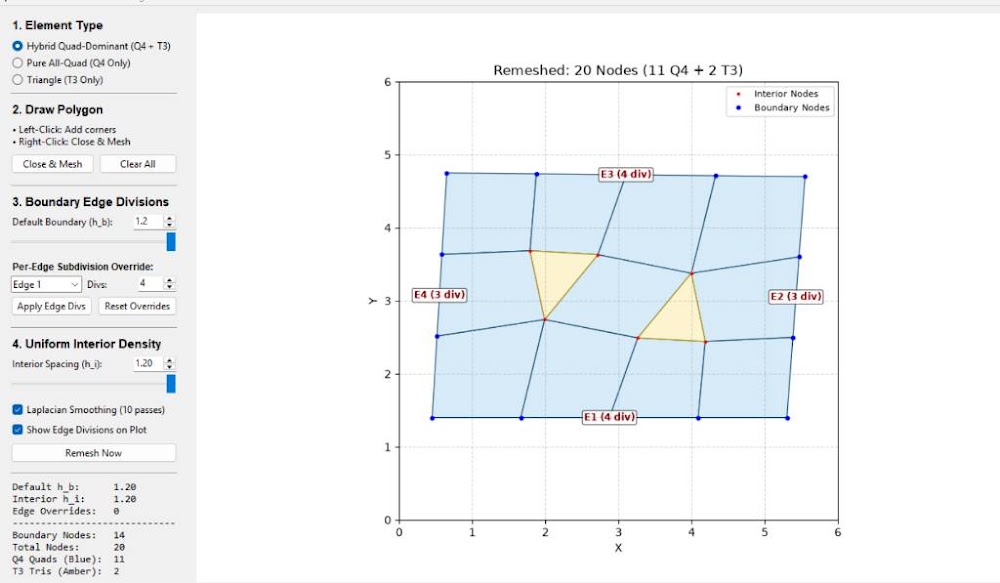

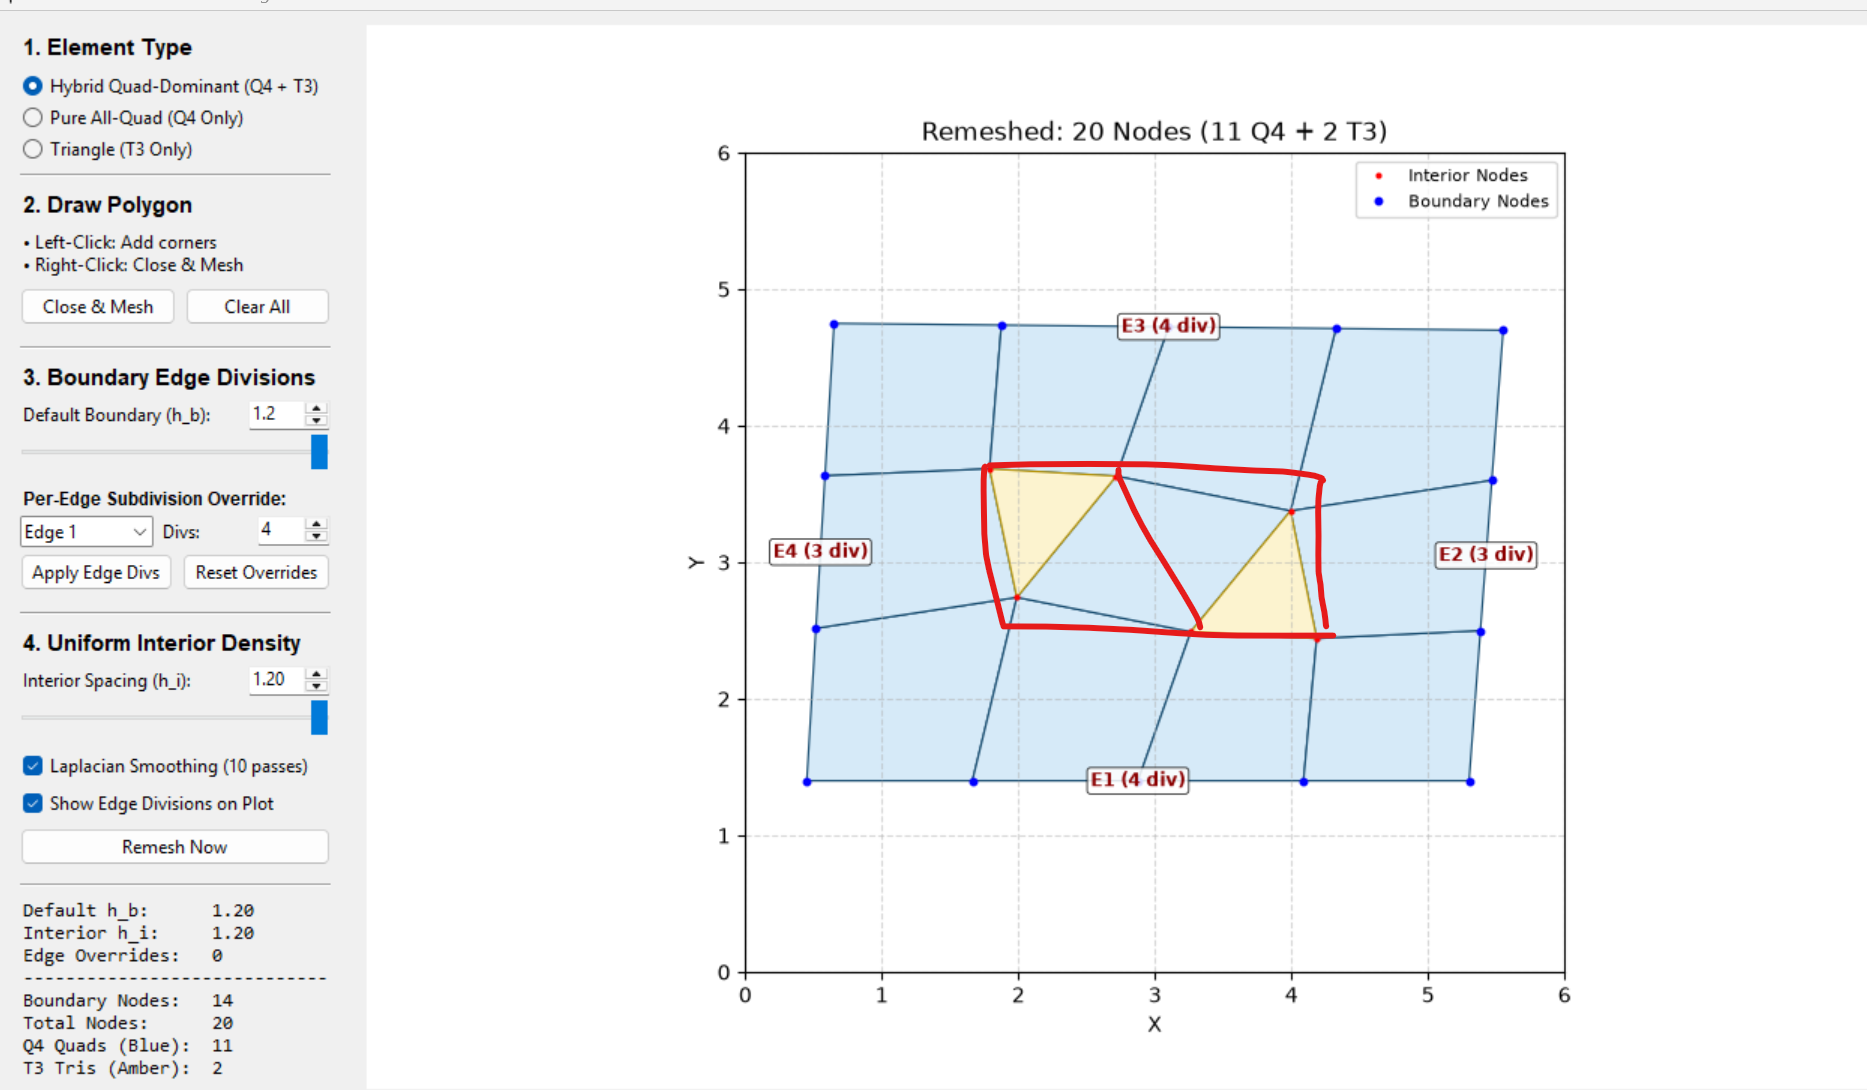


In the second image, you outlined the two interior quads that should form between the 6 interior nodes so the entire 4 × 3 grid becomes 12 pure quads (0 triangles) instead of 11 Q4 + 2 T3.

Why the Mesh Left 2 Yellow Triangles (T3)

1. Greedy Pair Merging Locked Out the Outer Triangles:
	• In the center strip between the 6 interior nodes, there are 4 triangles.
	• The greedy merger (candidate_pairs.sort(...)) scored the middle two triangles slightly higher in angle quality and merged them first into a single slanted blue quad.
	• Once those two middle triangles were claimed, the left and right triangles were left with no neighbor to pair with, forcing them to stay as 2 amber T3 triangles.
2. Unaligned Delaunay Diagonals:
	• Standard Delaunay triangulation connects points purely by circumcircle rules rather than grid alignment.
	• Because the upper-right interior node sits slightly low at (4.0, 3.35), Delaunay drew a diagonal across the right side that prevented a clean rectangular quad from forming where your right red box is drawn.


Maximize Quad Count + Better Diagonal Matching

In [5]:

import tkinter as tk
from tkinter import messagebox, ttk
import matplotlib.path as mpath
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
from matplotlib.collections import PolyCollection
from matplotlib.figure import Figure
import numpy as np
from scipy.spatial import Delaunay


# =========================================================
# 1. BASE T3 MESHER (Per-Edge Divisions + Uniform Interior)
# =========================================================
def ensure_ccw(vertices):
    x, y = vertices[:, 0], vertices[:, 1]
    signed_area = 0.5 * np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y)
    return vertices[::-1] if signed_area < 0 else vertices


def compute_edge_divisions(vertices, h_boundary, edge_div_overrides):
    """Returns the exact number of subdivisions for every polygon edge."""
    num_edges = len(vertices)
    divs = []
    for i in range(num_edges):
        if i in edge_div_overrides and edge_div_overrides[i] is not None:
            n_div = max(1, int(edge_div_overrides[i]))
        else:
            edge_len = np.linalg.norm(
                vertices[(i + 1) % num_edges] - vertices[i]
            )
            n_div = max(1, int(np.round(edge_len / h_boundary)))
        divs.append(n_div)
    return divs


def build_base_t3_edge_control(
    raw_vertices,
    h_boundary,
    h_interior,
    edge_div_overrides,
    use_smoothing,
    iterations,
):
    """Seeds boundary edges by exact division counts and interior uniformly by h_interior."""
    vertices = ensure_ccw(np.asarray(raw_vertices, dtype=float))
    num_edges = len(vertices)
    edge_divs = compute_edge_divisions(
        vertices, h_boundary, edge_div_overrides
    )

    # Step 1: Seed Boundary Nodes
    boundary_nodes = []
    for i in range(num_edges):
        p_start = vertices[i]
        p_end = vertices[(i + 1) % num_edges]
        n_div = edge_divs[i]
        for k in range(n_div):
            t = k / n_div
            boundary_nodes.append((1.0 - t) * p_start + t * p_end)
    boundary_nodes = np.array(boundary_nodes)

    # Step 2: Uniform Interior Node Seeding (No Distance Grading)
    poly_path = mpath.Path(vertices)
    xmin, ymin = vertices.min(axis=0)
    xmax, ymax = vertices.max(axis=0)
    dy = h_interior * np.sqrt(3) / 2.0

    interior_nodes = []
    row = 0
    y = ymin + dy
    while y < ymax:
        x_shift = (h_interior / 2.0) if (row % 2 == 1) else 0.0
        x = xmin + (h_interior / 2.0) + x_shift
        while x < xmax:
            pt = np.array([x, y])
            if poly_path.contains_point(pt):
                dist_to_b = np.min(
                    np.linalg.norm(boundary_nodes - pt, axis=1)
                )
                if dist_to_b > 0.50 * h_interior:
                    interior_nodes.append(pt)
            x += h_interior
        y += dy
        row += 1

    nodes = (
        np.vstack([boundary_nodes, np.array(interior_nodes)])
        if len(interior_nodes) > 0
        else boundary_nodes
    )
    num_b = len(boundary_nodes)

    # Step 3: Delaunay Triangulation + Polygon Clipping + CCW Ordering
    tri = Delaunay(nodes)
    valid_tris = []
    for simplex in tri.simplices:
        pts = nodes[simplex]
        if poly_path.contains_point(pts.mean(axis=0)):
            area2 = (pts[1, 0] - pts[0, 0]) * (pts[2, 1] - pts[0, 1]) - (
                pts[1, 1] - pts[0, 1]
            ) * (pts[2, 0] - pts[0, 0])
            if area2 > 1e-12:
                valid_tris.append(simplex)
            elif area2 < -1e-12:
                valid_tris.append([simplex[0], simplex[2], simplex[1]])
    tris = np.array(valid_tris, dtype=int)

    # Step 4: Optional Laplacian Smoothing (Boundary Nodes Stay Fixed)
    if use_smoothing and len(interior_nodes) > 0 and len(tris) > 0:
        nodes = apply_laplacian_smoothing(
            nodes, tris, set(range(num_b)), iterations
        )

    return nodes, tris, num_b, edge_divs


def apply_laplacian_smoothing(nodes, elements, fixed_node_ids, iterations):
    smoothed = nodes.copy()
    neighbors = {i: set() for i in range(len(smoothed))}
    for el in elements:
        k = len(el)
        for i in range(k):
            neighbors[el[i]].update([el[(i - 1) % k], el[(i + 1) % k]])

    for _ in range(iterations):
        new_pos = smoothed.copy()
        for idx in range(len(smoothed)):
            if idx not in fixed_node_ids and neighbors[idx]:
                nbrs = list(neighbors[idx])
                new_pos[idx] = 0.5 * smoothed[idx] + 0.5 * np.mean(
                    smoothed[nbrs], axis=0
                )
        smoothed = new_pos
    return smoothed


# =========================================================
# 2. HYBRID (Q4 + T3) & PURE Q4 CONVERTERS
# =========================================================
def merge_t3_to_hybrid_q4_t3(nodes, tris):
    edge_to_tris = {}
    for t_idx, tri in enumerate(tris):
        for i in range(3):
            edge = tuple(sorted((tri[i], tri[(i + 1) % 3])))
            edge_to_tris.setdefault(edge, []).append(t_idx)

    candidate_pairs = []
    for edge, adj_tris in edge_to_tris.items():
        if len(adj_tris) == 2:
            t1, t2 = adj_tris
            quad = form_ccw_quad(nodes, tris[t1], tris[t2], edge)
            if quad is not None:
                quality = quad_angle_quality(nodes[quad])
                if quality > 0.35:
                    candidate_pairs.append((quality, t1, t2, quad))

    candidate_pairs.sort(key=lambda x: x[0], reverse=True)
    used_tris = set()
    q4_elements = []
    for _, t1, t2, quad in candidate_pairs:
        if t1 not in used_tris and t2 not in used_tris:
            q4_elements.append(quad)
            used_tris.add(t1)
            used_tris.add(t2)

    t3_elements = [
        list(tris[i]) for i in range(len(tris)) if i not in used_tris
    ]
    return nodes, q4_elements, t3_elements


def form_ccw_quad(nodes, tri1, tri2, shared_edge):
    u, v = shared_edge
    opp1 = [n for n in tri1 if n not in shared_edge][0]
    opp2 = [n for n in tri2 if n not in shared_edge][0]
    quad = [u, opp1, v, opp2]
    pts = nodes[quad]

    crosses = []
    for i in range(4):
        v1 = pts[(i + 1) % 4] - pts[i]
        v2 = pts[(i + 2) % 4] - pts[(i + 1) % 4]
        crosses.append(v1[0] * v2[1] - v1[1] * v2[0])

    if all(c > 1e-12 for c in crosses):
        return quad
    if all(c < -1e-12 for c in crosses):
        return quad[::-1]
    return None


def quad_angle_quality(pts):
    max_dev = 0.0
    for k in range(4):
        v1 = pts[(k - 1) % 4] - pts[k]
        v2 = pts[(k + 1) % 4] - pts[k]
        cos_t = np.clip(
            np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2)),
            -1.0,
            1.0,
        )
        max_dev = max(max_dev, abs(90.0 - np.degrees(np.arccos(cos_t))))
    return max(0.0, 1.0 - max_dev / 90.0)


def subdivide_t3_to_pure_q4(nodes, tris, num_boundary_nodes):
    new_nodes = list(nodes)
    edge_midpoints = {}
    q4_elements = []
    boundary_midpoints = set()

    edge_counts = {}
    for tri in tris:
        for i in range(3):
            edge = tuple(sorted((tri[i], tri[(i + 1) % 3])))
            edge_counts[edge] = edge_counts.get(edge, 0) + 1

    def get_midpoint(u, v):
        edge = tuple(sorted((u, v)))
        if edge not in edge_midpoints:
            mid_pt = 0.5 * (nodes[u] + nodes[v])
            mid_idx = len(new_nodes)
            new_nodes.append(mid_pt)
            edge_midpoints[edge] = mid_idx
            if edge_counts[edge] == 1:
                boundary_midpoints.add(mid_idx)
        return edge_midpoints[edge]

    for n0, n1, n2 in tris:
        m01 = get_midpoint(n0, n1)
        m12 = get_midpoint(n1, n2)
        m20 = get_midpoint(n2, n0)
        c_idx = len(new_nodes)
        new_nodes.append((nodes[n0] + nodes[n1] + nodes[n2]) / 3.0)
        q4_elements.append([n0, m01, c_idx, m20])
        q4_elements.append([n1, m12, c_idx, m01])
        q4_elements.append([n2, m20, c_idx, m12])

    fixed_ids = set(range(num_boundary_nodes)) | boundary_midpoints
    return np.array(new_nodes), q4_elements, fixed_ids


# =========================================================
# 3. INTERACTIVE TKINTER PER-EDGE DIVISION REMESHER
# =========================================================
class PerEdgeDivisionRemesherApp:
    def __init__(self, root):
        self.root = root
        self.root.title('Interactive Remesher: Per-Edge Divisions & Uniform Interior')
        self.root.geometry('1050x710')

        self.clicked_pts = []
        self.polygon_closed = False
        self.edge_overrides = {}  # {edge_index: custom_num_divisions}
        self.current_edge_divs = []

        # --- Left Sidebar ---
        panel = ttk.Frame(root, padding=14)
        panel.pack(side=tk.LEFT, fill=tk.Y)

        # 1. Element Type
        ttk.Label(
            panel, text='1. Element Type', font=('Arial', 11, 'bold')
        ).pack(anchor=tk.W, pady=(0, 4))
        self.mode_var = tk.StringVar(value='HYBRID')
        for label, val in [
            ('Hybrid Quad-Dominant (Q4 + T3)', 'HYBRID'),
            ('Pure All-Quad (Q4 Only)', 'PURE_Q4'),
            ('Triangle (T3 Only)', 'T3'),
        ]:
            ttk.Radiobutton(
                panel,
                text=label,
                variable=self.mode_var,
                value=val,
                command=self.remesh,
            ).pack(anchor=tk.W)

        ttk.Separator(panel, orient=tk.HORIZONTAL).pack(fill=tk.X, pady=6)

        # 2. Polygon Drawing
        ttk.Label(
            panel, text='2. Draw Polygon', font=('Arial', 11, 'bold')
        ).pack(anchor=tk.W, pady=(2, 4))
        ttk.Label(
            panel,
            text='• Left-Click: Add corners\n• Right-Click: Close & Mesh',
            justify=tk.LEFT,
        ).pack(anchor=tk.W, pady=(0, 6))

        btn_row = ttk.Frame(panel)
        btn_row.pack(fill=tk.X, pady=(0, 8))
        ttk.Button(
            btn_row, text='Close & Mesh', command=self.close_and_mesh
        ).pack(side=tk.LEFT, expand=True, fill=tk.X, padx=(0, 3))
        ttk.Button(
            btn_row, text='Clear All', command=self.clear_canvas
        ).pack(side=tk.RIGHT, expand=True, fill=tk.X, padx=(3, 0))

        ttk.Separator(panel, orient=tk.HORIZONTAL).pack(fill=tk.X, pady=6)

        # 3. Boundary & Per-Edge Divisions
        ttk.Label(
            panel, text='3. Boundary Edge Divisions', font=('Arial', 11, 'bold')
        ).pack(anchor=tk.W, pady=(2, 4))

        b_row = ttk.Frame(panel)
        b_row.pack(fill=tk.X)
        ttk.Label(b_row, text='Default Boundary (h_b):').pack(side=tk.LEFT)
        self.hb_var = tk.DoubleVar(value=0.45)
        ttk.Spinbox(
            b_row,
            from_=0.12,
            to=1.50,
            increment=0.05,
            textvariable=self.hb_var,
            width=6,
            command=self.remesh,
        ).pack(side=tk.RIGHT)

        ttk.Scale(
            panel,
            from_=0.12,
            to=1.20,
            variable=self.hb_var,
            command=self.on_slider_drag,
        ).pack(fill=tk.X, pady=(2, 8))

        # Per-Edge Subdivision Override
        ttk.Label(
            panel, text='Per-Edge Subdivision Override:', font=('Arial', 9, 'bold')
        ).pack(anchor=tk.W)
        edge_row = ttk.Frame(panel)
        edge_row.pack(fill=tk.X, pady=(2, 4))
        self.edge_select = ttk.Combobox(edge_row, state='readonly', width=11)
        self.edge_select.pack(side=tk.LEFT, padx=(0, 4))
        self.edge_select.bind('<<ComboboxSelected>>', self.on_edge_selected)

        ttk.Label(edge_row, text='Divs:').pack(side=tk.LEFT)
        self.edge_div_var = tk.IntVar(value=6)
        ttk.Spinbox(
            edge_row,
            from_=1,
            to=50,
            textvariable=self.edge_div_var,
            width=5,
        ).pack(side=tk.RIGHT)

        edge_btn_row = ttk.Frame(panel)
        edge_btn_row.pack(fill=tk.X, pady=(0, 8))
        ttk.Button(
            edge_btn_row, text='Apply Edge Divs', command=self.apply_edge_override
        ).pack(side=tk.LEFT, expand=True, fill=tk.X, padx=(0, 3))
        ttk.Button(
            edge_btn_row, text='Reset Overrides', command=self.reset_edge_overrides
        ).pack(side=tk.RIGHT, expand=True, fill=tk.X, padx=(3, 0))

        ttk.Separator(panel, orient=tk.HORIZONTAL).pack(fill=tk.X, pady=6)

        # 4. Uniform Interior Mesh Density
        ttk.Label(
            panel, text='4. Uniform Interior Density', font=('Arial', 11, 'bold')
        ).pack(anchor=tk.W, pady=(2, 4))

        i_row = ttk.Frame(panel)
        i_row.pack(fill=tk.X)
        ttk.Label(i_row, text='Interior Spacing (h_i):').pack(side=tk.LEFT)
        self.hi_var = tk.DoubleVar(value=0.55)
        ttk.Spinbox(
            i_row,
            from_=0.15,
            to=1.50,
            increment=0.05,
            textvariable=self.hi_var,
            width=6,
            command=self.remesh,
        ).pack(side=tk.RIGHT)

        ttk.Scale(
            panel,
            from_=0.15,
            to=1.20,
            variable=self.hi_var,
            command=self.on_slider_drag,
        ).pack(fill=tk.X, pady=(2, 6))

        self.smooth_var = tk.BooleanVar(value=True)
        ttk.Checkbutton(
            panel,
            text='Laplacian Smoothing (10 passes)',
            variable=self.smooth_var,
            command=self.remesh,
        ).pack(anchor=tk.W, pady=(2, 4))

        self.show_edge_labels = tk.BooleanVar(value=True)
        ttk.Checkbutton(
            panel,
            text='Show Edge Divisions on Plot',
            variable=self.show_edge_labels,
            command=self.remesh,
        ).pack(anchor=tk.W, pady=(0, 6))

        ttk.Button(panel, text='Remesh Now', command=self.remesh).pack(
            fill=tk.X, pady=(0, 6)
        )

        ttk.Separator(panel, orient=tk.HORIZONTAL).pack(fill=tk.X, pady=6)

        # 5. Summary Report
        self.stats_label = ttk.Label(
            panel,
            text='Draw a closed polygon\nto set edge divisions.',
            font=('Consolas', 10),
            justify=tk.LEFT,
        )
        self.stats_label.pack(anchor=tk.W)

        # --- Right Canvas ---
        plot_frame = ttk.Frame(root, padding=10)
        plot_frame.pack(side=tk.RIGHT, fill=tk.BOTH, expand=True)

        self.fig = Figure(figsize=(6, 6), dpi=100)
        self.ax = self.fig.add_subplot(111)
        self.canvas = FigureCanvasTkAgg(self.fig, master=plot_frame)
        self.canvas.get_tk_widget().pack(fill=tk.BOTH, expand=True)
        self.canvas.mpl_connect('button_press_event', self.on_canvas_click)

        self.redraw_drawing_state()

    def setup_axes(self, title):
        self.ax.clear()
        self.ax.set_xlim(0.0, 6.0)
        self.ax.set_ylim(0.0, 6.0)
        self.ax.set_aspect('equal', adjustable='box')
        self.ax.grid(True, linestyle='--', alpha=0.5)
        self.ax.set_xlabel('X')
        self.ax.set_ylabel('Y')
        self.ax.set_title(title)

    def on_canvas_click(self, event):
        if event.inaxes != self.ax or self.polygon_closed:
            return
        if event.button == 1:
            x_snap = round(event.xdata * 20) / 20.0
            y_snap = round(event.ydata * 20) / 20.0
            self.clicked_pts.append([x_snap, y_snap])
            self.redraw_drawing_state()
        elif event.button == 3:
            self.close_and_mesh()

    def redraw_drawing_state(self):
        self.setup_axes(
            f'Left-Click Corners ({len(self.clicked_pts)} placed) | Right-Click to Mesh'
        )
        if len(self.clicked_pts) > 0:
            pts = np.array(self.clicked_pts)
            self.ax.plot(pts[:, 0], pts[:, 1], 'k-o', lw=1.5, markersize=5)
            self.ax.plot(pts[0, 0], pts[0, 1], 'go', markersize=8)
        self.canvas.draw()

    def close_and_mesh(self):
        if len(self.clicked_pts) < 3:
            messagebox.showwarning(
                'Not Enough Points', 'Click at least 3 corners first.'
            )
            return
        self.polygon_closed = True
        self.edge_overrides = {}
        ccw_pts = ensure_ccw(np.asarray(self.clicked_pts, dtype=float))
        self.clicked_pts = ccw_pts.tolist()

        edge_labels = [f'Edge {i + 1}' for i in range(len(self.clicked_pts))]
        self.edge_select['values'] = edge_labels
        self.edge_select.current(0)
        self.remesh()
        self.on_edge_selected()

    def clear_canvas(self):
        self.clicked_pts = []
        self.polygon_closed = False
        self.edge_overrides = {}
        self.current_edge_divs = []
        self.edge_select['values'] = []
        self.stats_label.config(
            text='Draw a closed polygon\nto set edge divisions.'
        )
        self.redraw_drawing_state()

    def on_edge_selected(self, _event=None):
        idx = self.edge_select.current()
        if idx >= 0 and idx < len(self.current_edge_divs):
            self.edge_div_var.set(self.current_edge_divs[idx])

    def apply_edge_override(self):
        if not self.polygon_closed:
            return
        idx = self.edge_select.current()
        if idx >= 0:
            self.edge_overrides[idx] = int(self.edge_div_var.get())
            self.remesh()

    def reset_edge_overrides(self):
        self.edge_overrides = {}
        self.remesh()
        self.on_edge_selected()

    def on_slider_drag(self, _event=None):
        self.hb_var.set(round(self.hb_var.get(), 2))
        self.hi_var.set(round(self.hi_var.get(), 2))
        self.remesh()
        self.on_edge_selected()

    def remesh(self):
        if not self.polygon_closed:
            return

        hb = max(0.10, float(self.hb_var.get()))
        hi = max(0.12, float(self.hi_var.get()))
        use_smooth = self.smooth_var.get()
        mode = self.mode_var.get()

        nodes, tris, num_b, edge_divs = build_base_t3_edge_control(
            self.clicked_pts,
            hb,
            hi,
            self.edge_overrides,
            use_smooth,
            iterations=10,
        )
        self.current_edge_divs = edge_divs

        if mode == 'T3':
            q4_els, t3_els = [], [list(t) for t in tris]
        elif mode == 'HYBRID':
            nodes, q4_els, t3_els = merge_t3_to_hybrid_q4_t3(nodes, tris)
            if use_smooth:
                nodes = apply_laplacian_smoothing(
                    nodes, q4_els + t3_els, set(range(num_b)), 10
                )
        else:  # PURE_Q4
            nodes, q4_els, fixed_ids = subdivide_t3_to_pure_q4(
                nodes, tris, num_b
            )
            t3_els = []
            if use_smooth:
                nodes = apply_laplacian_smoothing(nodes, q4_els, fixed_ids, 10)

        # In Pure Q4 mode, each boundary segment is split into 2 by midpoint subdivision
        display_divs = (
            [d * 2 for d in edge_divs] if mode == 'PURE_Q4' else edge_divs
        )
        display_num_b = num_b * 2 if mode == 'PURE_Q4' else num_b

        total_els = len(q4_els) + len(t3_els)
        report = (
            f'Default h_b:      {hb:.2f}\n'
            f'Interior h_i:     {hi:.2f}\n'
            f'Edge Overrides:   {len(self.edge_overrides)}\n'
            f'-----------------------------\n'
            f'Boundary Nodes:   {display_num_b}\n'
            f'Total Nodes:      {len(nodes)}\n'
            f'Q4 Quads (Blue):  {len(q4_els)}\n'
            f'T3 Tris (Amber):  {len(t3_els)}\n'
            f'Total Elements:   {total_els}\n'
            f'Reissner-Mindlin: {len(nodes) * 3} DOFs'
        )
        self.stats_label.config(text=report)

        self.setup_axes(
            f'Remeshed: {len(nodes)} Nodes ({len(q4_els)} Q4 + {len(t3_els)} T3)'
        )
        if q4_els:
            self.ax.add_collection(
                PolyCollection(
                    [nodes[el] for el in q4_els],
                    facecolors='#d6eaf8',
                    edgecolors='#1b4f72',
                    linewidths=0.85,
                )
            )
        if t3_els:
            self.ax.add_collection(
                PolyCollection(
                    [nodes[el] for el in t3_els],
                    facecolors='#fcf3cf',
                    edgecolors='#b7950b',
                    linewidths=0.85,
                )
            )

        # Plot interior nodes in red, boundary nodes in dark blue
        self.ax.plot(
            nodes[num_b:, 0],
            nodes[num_b:, 1],
            'ro',
            markersize=2.0,
            label='Interior Nodes',
        )
        self.ax.plot(
            nodes[:num_b, 0],
            nodes[:num_b, 1],
            'bo',
            markersize=3.2,
            label='Boundary Nodes',
        )

        # Show Edge ID + Number of Divisions on every boundary edge
        if self.show_edge_labels.get():
            pts = np.asarray(self.clicked_pts)
            n_pts = len(pts)
            for i in range(n_pts):
                mid = 0.5 * (pts[i] + pts[(i + 1) % n_pts])
                star = '*' if i in self.edge_overrides else ''
                tag = f'E{i + 1} ({display_divs[i]} div){star}'
                self.ax.text(
                    mid[0],
                    mid[1],
                    tag,
                    fontsize=8.5,
                    fontweight='bold',
                    color='darkred',
                    ha='center',
                    va='center',
                    bbox=dict(
                        boxstyle='round,pad=0.2', fc='white', alpha=0.85, lw=0.6
                    ),
                )

        self.ax.legend(loc='upper right', fontsize=8)
        self.canvas.draw()





def merge_t3_to_hybrid_q4_t3(nodes, tris):
    """Pairs T3 triangles into Q4 quads while prioritizing triangles with fewer options."""
    edge_to_tris = {}
    for t_idx, tri in enumerate(tris):
        for i in range(3):
            edge = tuple(sorted((tri[i], tri[(i + 1) % 3])))
            edge_to_tris.setdefault(edge, []).append(t_idx)

    # Find all valid candidate quad pairs
    raw_pairs = []
    tri_partner_count = {i: 0 for i in range(len(tris))}
    for edge, adj_tris in edge_to_tris.items():
        if len(adj_tris) == 2:
            t1, t2 = adj_tris
            quad = form_ccw_quad(nodes, tris[t1], tris[t2], edge)
            if quad is not None:
                quality = quad_angle_quality(nodes[quad])
                if quality > 0.25:
                    raw_pairs.append((quality, t1, t2, quad))
                    tri_partner_count[t1] += 1
                    tri_partner_count[t2] += 1

    # Prioritize triangles that have only 1 valid partner (prevents orphan T3s)
    scored_pairs = []
    for quality, t1, t2, quad in raw_pairs:
        min_options = min(tri_partner_count[t1], tri_partner_count[t2])
        priority = (1 if min_options == 1 else 0, quality)
        scored_pairs.append((priority, t1, t2, quad))

    scored_pairs.sort(key=lambda x: x[0], reverse=True)

    used_tris = set()
    q4_elements = []
    for _, t1, t2, quad in scored_pairs:
        if t1 not in used_tris and t2 not in used_tris:
            q4_elements.append(quad)
            used_tris.add(t1)
            used_tris.add(t2)

    t3_elements = [
        list(tris[i]) for i in range(len(tris)) if i not in used_tris
    ]
    return nodes, q4_elements, t3_elements

if __name__ == '__main__':
    root = tk.Tk()
    app = PerEdgeDivisionRemesherApp(root)
    root.mainloop()


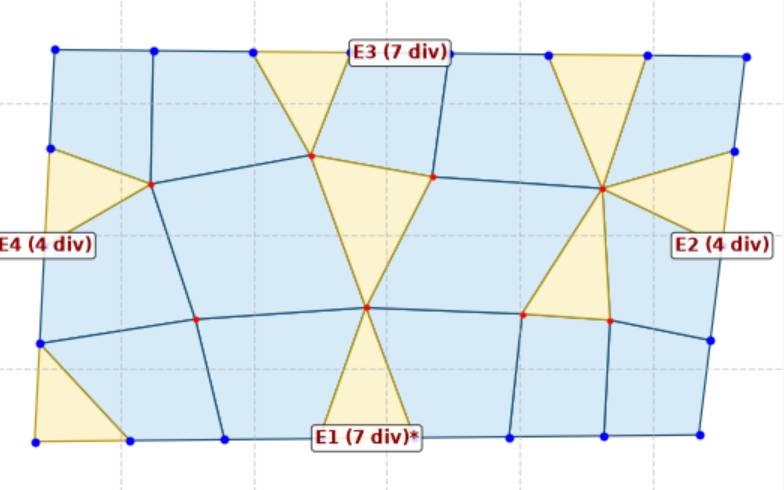
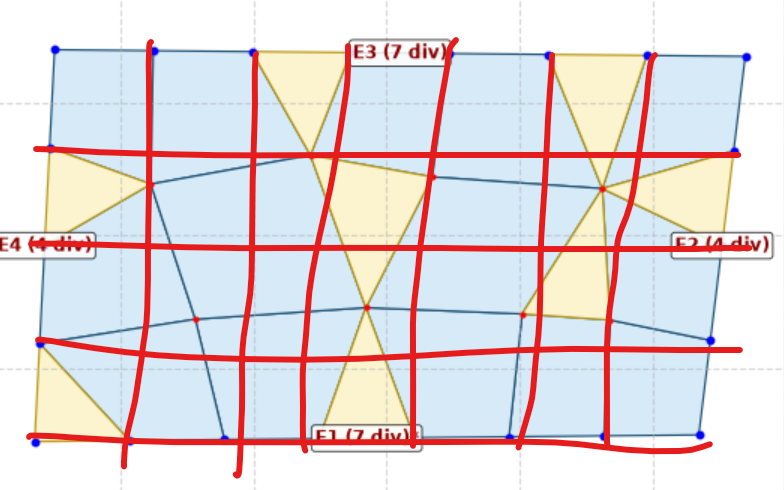

 Transfinite Interpolation (TFI) structured mapped quad meshing (for 4-sided polygons with matching opposite divisions like 7 × 4) with per-edge subdivision overrides and unstructured hybrid (Q4 + T3) / triangle (T3) fallback for arbitrary polygons.

In [6]:
import tkinter as tk
from tkinter import messagebox, ttk
import matplotlib.path as mpath
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
from matplotlib.collections import PolyCollection
from matplotlib.figure import Figure
import numpy as np
from scipy.spatial import Delaunay


# =========================================================
# 1. GEOMETRY, EDGE DIVISIONS & TFI STRUCTURED QUAD MESHER
# =========================================================
def ensure_ccw(vertices):
    x, y = vertices[:, 0], vertices[:, 1]
    signed_area = 0.5 * np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y)
    return vertices[::-1] if signed_area < 0 else vertices


def compute_edge_divisions(vertices, h_boundary, edge_div_overrides):
    """Returns the exact number of subdivisions for every polygon edge."""
    num_edges = len(vertices)
    divs = []
    for i in range(num_edges):
        if i in edge_div_overrides and edge_div_overrides[i] is not None:
            n_div = max(1, int(edge_div_overrides[i]))
        else:
            edge_len = np.linalg.norm(
                vertices[(i + 1) % num_edges] - vertices[i]
            )
            n_div = max(1, int(np.round(edge_len / h_boundary)))
        divs.append(n_div)
    return divs


def try_structured_tfi_quad_mesh(raw_vertices, edge_divs):
    """Generates a structured mapped Q4 quad mesh (Transfinite Interpolation)
    whenever the polygon has 4 sides and opposite edges have equal divisions:
        div[E1] == div[E3]  and  div[E2] == div[E4]
    Returns (nodes, q4_els, num_boundary_nodes) or None if not applicable.
    """
    vertices = ensure_ccw(np.asarray(raw_vertices, dtype=float))
    if len(vertices) != 4:
        return None

    n1, n2, n3, n4 = edge_divs
    if n1 != n3 or n2 != n4:
        return None

    nu, nv = n1, n2
    v0, v1, v2, v3 = vertices[0], vertices[1], vertices[2], vertices[3]

    grid_idx = np.full((nv + 1, nu + 1), -1, dtype=int)
    boundary_nodes = []
    interior_nodes = []

    # Bottom edge E1 (j = 0, i = 0 .. nu - 1)
    for i in range(nu):
        u = i / nu
        grid_idx[0, i] = len(boundary_nodes)
        boundary_nodes.append((1.0 - u) * v0 + u * v1)

    # Right edge E2 (i = nu, j = 0 .. nv - 1)
    for j in range(nv):
        v = j / nv
        grid_idx[j, nu] = len(boundary_nodes)
        boundary_nodes.append((1.0 - v) * v1 + v * v2)

    # Top edge E3 (j = nv, i = nu .. 1)
    for k in range(nu):
        i = nu - k
        u = i / nu
        grid_idx[nv, i] = len(boundary_nodes)
        boundary_nodes.append((1.0 - u) * v3 + u * v2)

    # Left edge E4 (i = 0, j = nv .. 1)
    for k in range(nv):
        j = nv - k
        v = j / nv
        grid_idx[j, 0] = len(boundary_nodes)
        boundary_nodes.append((1.0 - v) * v0 + v * v3)

    num_b = len(boundary_nodes)

    # Interior grid nodes via Bilinear Coons Patch (Transfinite Interpolation)
    for j in range(1, nv):
        v = j / nv
        for i in range(1, nu):
            u = i / nu
            pt = (
                (1.0 - u) * (1.0 - v) * v0
                + u * (1.0 - v) * v1
                + u * v * v2
                + (1.0 - u) * v * v3
            )
            grid_idx[j, i] = num_b + len(interior_nodes)
            interior_nodes.append(pt)

    nodes = (
        np.vstack([boundary_nodes, interior_nodes])
        if interior_nodes
        else np.array(boundary_nodes)
    )

    # Build CCW Q4 Quad Elements
    q4_els = []
    for j in range(nv):
        for i in range(nu):
            n00 = int(grid_idx[j, i])
            n10 = int(grid_idx[j, i + 1])
            n11 = int(grid_idx[j + 1, i + 1])
            n01 = int(grid_idx[j + 1, i])
            q4_els.append([n00, n10, n11, n01])

    return nodes, q4_els, num_b


# =========================================================
# 2. UNSTRUCTURED BASE T3 & HYBRID / PURE Q4 CONVERTERS
# =========================================================
def build_base_t3_edge_control(
    raw_vertices,
    h_boundary,
    h_interior,
    edge_div_overrides,
    use_smoothing,
    iterations,
):
    """Seeds boundary edges by exact division counts and interior uniformly by h_interior."""
    vertices = ensure_ccw(np.asarray(raw_vertices, dtype=float))
    num_edges = len(vertices)
    edge_divs = compute_edge_divisions(
        vertices, h_boundary, edge_div_overrides
    )

    boundary_nodes = []
    for i in range(num_edges):
        p_start = vertices[i]
        p_end = vertices[(i + 1) % num_edges]
        n_div = edge_divs[i]
        for k in range(n_div):
            t = k / n_div
            boundary_nodes.append((1.0 - t) * p_start + t * p_end)
    boundary_nodes = np.array(boundary_nodes)

    poly_path = mpath.Path(vertices)
    xmin, ymin = vertices.min(axis=0)
    xmax, ymax = vertices.max(axis=0)
    dy = h_interior * np.sqrt(3) / 2.0

    interior_nodes = []
    row = 0
    y = ymin + dy
    while y < ymax:
        x_shift = (h_interior / 2.0) if (row % 2 == 1) else 0.0
        x = xmin + (h_interior / 2.0) + x_shift
        while x < xmax:
            pt = np.array([x, y])
            if poly_path.contains_point(pt):
                dist_to_b = np.min(
                    np.linalg.norm(boundary_nodes - pt, axis=1)
                )
                if dist_to_b > 0.50 * h_interior:
                    interior_nodes.append(pt)
            x += h_interior
        y += dy
        row += 1

    nodes = (
        np.vstack([boundary_nodes, np.array(interior_nodes)])
        if len(interior_nodes) > 0
        else boundary_nodes
    )
    num_b = len(boundary_nodes)

    tri = Delaunay(nodes)
    valid_tris = []
    for simplex in tri.simplices:
        pts = nodes[simplex]
        if poly_path.contains_point(pts.mean(axis=0)):
            area2 = (pts[1, 0] - pts[0, 0]) * (pts[2, 1] - pts[0, 1]) - (
                pts[1, 1] - pts[0, 1]
            ) * (pts[2, 0] - pts[0, 0])
            if area2 > 1e-12:
                valid_tris.append(simplex)
            elif area2 < -1e-12:
                valid_tris.append([simplex[0], simplex[2], simplex[1]])
    tris = np.array(valid_tris, dtype=int)

    if use_smoothing and len(interior_nodes) > 0 and len(tris) > 0:
        nodes = apply_laplacian_smoothing(
            nodes, tris, set(range(num_b)), iterations
        )

    return nodes, tris, num_b, edge_divs


def apply_laplacian_smoothing(nodes, elements, fixed_node_ids, iterations):
    smoothed = nodes.copy()
    neighbors = {i: set() for i in range(len(smoothed))}
    for el in elements:
        k = len(el)
        for i in range(k):
            neighbors[el[i]].update([el[(i - 1) % k], el[(i + 1) % k]])

    for _ in range(iterations):
        new_pos = smoothed.copy()
        for idx in range(len(smoothed)):
            if idx not in fixed_node_ids and neighbors[idx]:
                nbrs = list(neighbors[idx])
                new_pos[idx] = 0.5 * smoothed[idx] + 0.5 * np.mean(
                    smoothed[nbrs], axis=0
                )
        smoothed = new_pos
    return smoothed


def merge_t3_to_hybrid_q4_t3(nodes, tris):
    """Pairs T3 triangles into Q4 quads while prioritizing triangles with fewer options."""
    edge_to_tris = {}
    for t_idx, tri in enumerate(tris):
        for i in range(3):
            edge = tuple(sorted((tri[i], tri[(i + 1) % 3])))
            edge_to_tris.setdefault(edge, []).append(t_idx)

    raw_pairs = []
    tri_partner_count = {i: 0 for i in range(len(tris))}
    for edge, adj_tris in edge_to_tris.items():
        if len(adj_tris) == 2:
            t1, t2 = adj_tris
            quad = form_ccw_quad(nodes, tris[t1], tris[t2], edge)
            if quad is not None:
                quality = quad_angle_quality(nodes[quad])
                if quality > 0.25:
                    raw_pairs.append((quality, t1, t2, quad))
                    tri_partner_count[t1] += 1
                    tri_partner_count[t2] += 1

    scored_pairs = []
    for quality, t1, t2, quad in raw_pairs:
        min_options = min(tri_partner_count[t1], tri_partner_count[t2])
        priority = (1 if min_options == 1 else 0, quality)
        scored_pairs.append((priority, t1, t2, quad))

    scored_pairs.sort(key=lambda x: x[0], reverse=True)

    used_tris = set()
    q4_elements = []
    for _, t1, t2, quad in scored_pairs:
        if t1 not in used_tris and t2 not in used_tris:
            q4_elements.append(quad)
            used_tris.add(t1)
            used_tris.add(t2)

    t3_elements = [
        list(tris[i]) for i in range(len(tris)) if i not in used_tris
    ]
    return nodes, q4_elements, t3_elements


def form_ccw_quad(nodes, tri1, tri2, shared_edge):
    u, v = shared_edge
    opp1 = [n for n in tri1 if n not in shared_edge][0]
    opp2 = [n for n in tri2 if n not in shared_edge][0]
    quad = [u, opp1, v, opp2]
    pts = nodes[quad]

    crosses = []
    for i in range(4):
        v1 = pts[(i + 1) % 4] - pts[i]
        v2 = pts[(i + 2) % 4] - pts[(i + 1) % 4]
        crosses.append(v1[0] * v2[1] - v1[1] * v2[0])

    if all(c > 1e-12 for c in crosses):
        return quad
    if all(c < -1e-12 for c in crosses):
        return quad[::-1]
    return None


def quad_angle_quality(pts):
    max_dev = 0.0
    for k in range(4):
        v1 = pts[(k - 1) % 4] - pts[k]
        v2 = pts[(k + 1) % 4] - pts[k]
        cos_t = np.clip(
            np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2)),
            -1.0,
            1.0,
        )
        max_dev = max(max_dev, abs(90.0 - np.degrees(np.arccos(cos_t))))
    return max(0.0, 1.0 - max_dev / 90.0)


def subdivide_t3_to_pure_q4(nodes, tris, num_boundary_nodes):
    new_nodes = list(nodes)
    edge_midpoints = {}
    q4_elements = []
    boundary_midpoints = set()

    edge_counts = {}
    for tri in tris:
        for i in range(3):
            edge = tuple(sorted((tri[i], tri[(i + 1) % 3])))
            edge_counts[edge] = edge_counts.get(edge, 0) + 1

def subdivide_t3_to_pure_q4(nodes, tris, num_boundary_nodes):
    new_nodes = list(nodes)
    edge_midpoints = {}
    q4_elements = []
    boundary_midpoints = set()

    edge_counts = {}
    for tri in tris:
        for i in range(3):
            edge = tuple(sorted((tri[i], tri[(i + 1) % 3])))
            edge_counts[edge] = edge_counts.get(edge, 0) + 1

    def get_midpoint(u, v):
        edge = tuple(sorted((u, v)))
        if edge not in edge_midpoints:
            mid_pt = 0.5 * (nodes[u] + nodes[v])
            mid_idx = len(new_nodes)
            new_nodes.append(mid_pt)
            edge_midpoints[edge] = mid_idx
            if edge_counts[edge] == 1:
                boundary_midpoints.add(mid_idx)
        return edge_midpoints[edge]

    for n0, n1, n2 in tris:
        m01 = get_midpoint(n0, n1)
        m12 = get_midpoint(n1, n2)
        m20 = get_midpoint(n2, n0)
        c_idx = len(new_nodes)
        new_nodes.append((nodes[n0] + nodes[n1] + nodes[n2]) / 3.0)
        q4_elements.append([n0, m01, c_idx, m20])
        q4_elements.append([n1, m12, c_idx, m01])
        q4_elements.append([n2, m20, c_idx, m12])

    fixed_ids = set(range(num_boundary_nodes)) | boundary_midpoints
    return np.array(new_nodes), q4_elements, fixed_ids


# =========================================================
# 3. INTERACTIVE TKINTER REMESHING APPLICATION
# =========================================================
class PerEdgeDivisionRemesherApp:
    def __init__(self, root):
        self.root = root
        self.root.title('Interactive Remesher: Mapped Q4 & Per-Edge Divisions')
        self.root.geometry('1050x720')

        self.clicked_pts = []
        self.polygon_closed = False
        self.edge_overrides = {}
        self.current_edge_divs = []

        # --- Left Sidebar ---
        panel = ttk.Frame(root, padding=14)
        panel.pack(side=tk.LEFT, fill=tk.Y)

        # 1. Element Type
        ttk.Label(
            panel, text='1. Element Type', font=('Arial', 11, 'bold')
        ).pack(anchor=tk.W, pady=(0, 4))
        self.mode_var = tk.StringVar(value='HYBRID')
        for label, val in [
            ('Hybrid / Mapped Quad (Q4 + T3)', 'HYBRID'),
            ('Pure All-Quad (Q4 Only)', 'PURE_Q4'),
            ('Triangle (T3 Only)', 'T3'),
        ]:
            ttk.Radiobutton(
                panel,
                text=label,
                variable=self.mode_var,
                value=val,
                command=self.remesh,
            ).pack(anchor=tk.W)

        ttk.Separator(panel, orient=tk.HORIZONTAL).pack(fill=tk.X, pady=6)

        # 2. Polygon Drawing
        ttk.Label(
            panel, text='2. Draw Polygon', font=('Arial', 11, 'bold')
        ).pack(anchor=tk.W, pady=(2, 4))
        ttk.Label(
            panel,
            text='• Left-Click: Add corners\n• Right-Click: Close & Mesh',
            justify=tk.LEFT,
        ).pack(anchor=tk.W, pady=(0, 6))

        btn_row = ttk.Frame(panel)
        btn_row.pack(fill=tk.X, pady=(0, 8))
        ttk.Button(
            btn_row, text='Close & Mesh', command=self.close_and_mesh
        ).pack(side=tk.LEFT, expand=True, fill=tk.X, padx=(0, 3))
        ttk.Button(
            btn_row, text='Clear All', command=self.clear_canvas
        ).pack(side=tk.RIGHT, expand=True, fill=tk.X, padx=(3, 0))

        ttk.Separator(panel, orient=tk.HORIZONTAL).pack(fill=tk.X, pady=6)

        # 3. Boundary & Per-Edge Divisions
        ttk.Label(
            panel, text='3. Boundary Edge Divisions', font=('Arial', 11, 'bold')
        ).pack(anchor=tk.W, pady=(2, 4))

        b_row = ttk.Frame(panel)
        b_row.pack(fill=tk.X)
        ttk.Label(b_row, text='Default Boundary (h_b):').pack(side=tk.LEFT)
        self.hb_var = tk.DoubleVar(value=0.65)
        ttk.Spinbox(
            b_row,
            from_=0.12,
            to=1.50,
            increment=0.05,
            textvariable=self.hb_var,
            width=6,
            command=self.remesh,
        ).pack(side=tk.RIGHT)

        ttk.Scale(
            panel,
            from_=0.12,
            to=1.40,
            variable=self.hb_var,
            command=self.on_slider_drag,
        ).pack(fill=tk.X, pady=(2, 8))

        # Per-Edge Subdivision Override
        ttk.Label(
            panel, text='Per-Edge Subdivision Override:', font=('Arial', 9, 'bold')
        ).pack(anchor=tk.W)
        edge_row = ttk.Frame(panel)
        edge_row.pack(fill=tk.X, pady=(2, 4))
        self.edge_select = ttk.Combobox(edge_row, state='readonly', width=11)
        self.edge_select.pack(side=tk.LEFT, padx=(0, 4))
        self.edge_select.bind('<<ComboboxSelected>>', self.on_edge_selected)

        ttk.Label(edge_row, text='Divs:').pack(side=tk.LEFT)
        self.edge_div_var = tk.IntVar(value=7)
        ttk.Spinbox(
            edge_row,
            from_=1,
            to=50,
            textvariable=self.edge_div_var,
            width=5,
        ).pack(side=tk.RIGHT)

        edge_btn_row = ttk.Frame(panel)
        edge_btn_row.pack(fill=tk.X, pady=(0, 8))
        ttk.Button(
            edge_btn_row, text='Apply Edge Divs', command=self.apply_edge_override
        ).pack(side=tk.LEFT, expand=True, fill=tk.X, padx=(0, 3))
        ttk.Button(
            edge_btn_row, text='Reset Overrides', command=self.reset_edge_overrides
        ).pack(side=tk.RIGHT, expand=True, fill=tk.X, padx=(3, 0))

        ttk.Separator(panel, orient=tk.HORIZONTAL).pack(fill=tk.X, pady=6)

        # 4. Uniform Interior Mesh Density (used when unstructured fallback runs)
        ttk.Label(
            panel, text='4. Unstructured Interior Density', font=('Arial', 11, 'bold')
        ).pack(anchor=tk.W, pady=(2, 4))

        i_row = ttk.Frame(panel)
        i_row.pack(fill=tk.X)
        ttk.Label(i_row, text='Interior Spacing (h_i):').pack(side=tk.LEFT)
        self.hi_var = tk.DoubleVar(value=0.65)
        ttk.Spinbox(
            i_row,
            from_=0.15,
            to=1.50,
            increment=0.05,
            textvariable=self.hi_var,
            width=6,
            command=self.remesh,
        ).pack(side=tk.RIGHT)

        ttk.Scale(
            panel,
            from_=0.15,
            to=1.40,
            variable=self.hi_var,
            command=self.on_slider_drag,
        ).pack(fill=tk.X, pady=(2, 6))

        self.smooth_var = tk.BooleanVar(value=True)
        ttk.Checkbutton(
            panel,
            text='Laplacian Smoothing (10 passes)',
            variable=self.smooth_var,
            command=self.remesh,
        ).pack(anchor=tk.W, pady=(2, 4))

        self.show_edge_labels = tk.BooleanVar(value=True)
        ttk.Checkbutton(
            panel,
            text='Show Edge Divisions on Plot',
            variable=self.show_edge_labels,
            command=self.remesh,
        ).pack(anchor=tk.W, pady=(0, 6))

        ttk.Button(panel, text='Remesh Now', command=self.remesh).pack(
            fill=tk.X, pady=(0, 6)
        )

        ttk.Separator(panel, orient=tk.HORIZONTAL).pack(fill=tk.X, pady=6)

        # 5. Summary Report
        self.stats_label = ttk.Label(
            panel,
            text='Draw a closed polygon\nto start remeshing.',
            font=('Consolas', 10),
            justify=tk.LEFT,
        )
        self.stats_label.pack(anchor=tk.W)

        # --- Right Canvas ---
        plot_frame = ttk.Frame(root, padding=10)
        plot_frame.pack(side=tk.RIGHT, fill=tk.BOTH, expand=True)

        self.fig = Figure(figsize=(6, 6), dpi=100)
        self.ax = self.fig.add_subplot(111)
        self.canvas = FigureCanvasTkAgg(self.fig, master=plot_frame)
        self.canvas.get_tk_widget().pack(fill=tk.BOTH, expand=True)
        self.canvas.mpl_connect('button_press_event', self.on_canvas_click)

        self.redraw_drawing_state()

    def setup_axes(self, title):
        self.ax.clear()
        self.ax.set_xlim(0.0, 6.0)
        self.ax.set_ylim(0.0, 6.0)
        self.ax.set_aspect('equal', adjustable='box')
        self.ax.grid(True, linestyle='--', alpha=0.5)
        self.ax.set_xlabel('X')
        self.ax.set_ylabel('Y')
        self.ax.set_title(title)

    def on_canvas_click(self, event):
        if event.inaxes != self.ax or self.polygon_closed:
            return
        if event.button == 1:
            x_snap = round(event.xdata * 20) / 20.0
            y_snap = round(event.ydata * 20) / 20.0
            self.clicked_pts.append([x_snap, y_snap])
            self.redraw_drawing_state()
        elif event.button == 3:
            self.close_and_mesh()

    def redraw_drawing_state(self):
        self.setup_axes(
            f'Left-Click Corners ({len(self.clicked_pts)} placed) | Right-Click to Mesh'
        )
        if len(self.clicked_pts) > 0:
            pts = np.array(self.clicked_pts)
            self.ax.plot(pts[:, 0], pts[:, 1], 'k-o', lw=1.5, markersize=5)
            self.ax.plot(pts[0, 0], pts[0, 1], 'go', markersize=8)
        self.canvas.draw()

    def close_and_mesh(self):
        if len(self.clicked_pts) < 3:
            messagebox.showwarning(
                'Not Enough Points', 'Click at least 3 corners first.'
            )
            return
        self.polygon_closed = True
        self.edge_overrides = {}
        ccw_pts = ensure_ccw(np.asarray(self.clicked_pts, dtype=float))
        self.clicked_pts = ccw_pts.tolist()

        edge_labels = [f'Edge {i + 1}' for i in range(len(self.clicked_pts))]
        self.edge_select['values'] = edge_labels
        self.edge_select.current(0)
        self.remesh()
        self.on_edge_selected()

    def clear_canvas(self):
        self.clicked_pts = []
        self.polygon_closed = False
        self.edge_overrides = {}
        self.current_edge_divs = []
        self.edge_select['values'] = []
        self.stats_label.config(
            text='Draw a closed polygon\nto start remeshing.'
        )
        self.redraw_drawing_state()

    def on_edge_selected(self, _event=None):
        idx = self.edge_select.current()
        if idx >= 0 and idx < len(self.current_edge_divs):
            self.edge_div_var.set(self.current_edge_divs[idx])

    def apply_edge_override(self):
        if not self.polygon_closed:
            return
        idx = self.edge_select.current()
        if idx >= 0:
            self.edge_overrides[idx] = int(self.edge_div_var.get())
            self.remesh()

    def reset_edge_overrides(self):
        self.edge_overrides = {}
        self.remesh()
        self.on_edge_selected()

    def on_slider_drag(self, _event=None):
        self.hb_var.set(round(self.hb_var.get(), 2))
        self.hi_var.set(round(self.hi_var.get(), 2))
        self.remesh()
        self.on_edge_selected()

    def remesh(self):
        if not self.polygon_closed:
            return

        hb = max(0.10, float(self.hb_var.get()))
        hi = max(0.12, float(self.hi_var.get()))
        use_smooth = self.smooth_var.get()
        mode = self.mode_var.get()

        ccw_verts = ensure_ccw(np.asarray(self.clicked_pts, dtype=float))
        edge_divs = compute_edge_divisions(ccw_verts, hb, self.edge_overrides)
        self.current_edge_divs = edge_divs

        # Use structured TFI mapped quad grid when 4-sided and opposite edges match
        tfi_result = (
            try_structured_tfi_quad_mesh(ccw_verts, edge_divs)
            if mode in ('HYBRID', 'PURE_Q4')
            else None
        )

        if tfi_result is not None:
            nodes, q4_els, num_b = tfi_result
            t3_els = []
            if use_smooth:
                nodes = apply_laplacian_smoothing(
                    nodes, q4_els, set(range(num_b)), 10
                )
            display_divs = edge_divs
            display_num_b = num_b
            mesh_type_tag = 'Mapped TFI Grid'
        else:
            nodes, tris, num_b, edge_divs = build_base_t3_edge_control(
                self.clicked_pts,
                hb,
                hi,
                self.edge_overrides,
                use_smooth,
                iterations=10,
            )
            if mode == 'T3':
                q4_els, t3_els = [], [list(t) for t in tris]
            elif mode == 'HYBRID':
                nodes, q4_els, t3_els = merge_t3_to_hybrid_q4_t3(nodes, tris)
                if use_smooth:
                    nodes = apply_laplacian_smoothing(
                        nodes, q4_els + t3_els, set(range(num_b)), 10
                    )
            else:  # PURE_Q4
                nodes, q4_els, fixed_ids = subdivide_t3_to_pure_q4(
                    nodes, tris, num_b
                )
                t3_els = []
                if use_smooth:
                    nodes = apply_laplacian_smoothing(
                        nodes, q4_els, fixed_ids, 10
                    )

            display_divs = (
                [d * 2 for d in edge_divs] if mode == 'PURE_Q4' else edge_divs
            )
            display_num_b = num_b * 2 if mode == 'PURE_Q4' else num_b
            mesh_type_tag = 'Unstructured'

        total_els = len(q4_els) + len(t3_els)
        report = (
            f'Mesh Type:        {mesh_type_tag}\n'
            f'Default h_b:      {hb:.2f}\n'
            f'Interior h_i:     {hi:.2f}\n'
            f'-----------------------------\n'
            f'Boundary Nodes:   {display_num_b}\n'
            f'Total Nodes:      {len(nodes)}\n'
            f'Q4 Quads (Blue):  {len(q4_els)}\n'
            f'T3 Tris (Amber):  {len(t3_els)}\n'
            f'Total Elements:   {total_els}\n'
            f'Reissner-Mindlin: {len(nodes) * 3} DOFs'
        )
        self.stats_label.config(text=report)

        self.setup_axes(
            f'Remeshed ({mesh_type_tag}): {len(nodes)} Nodes ({len(q4_els)} Q4 + {len(t3_els)} T3)'
        )
        if q4_els:
            self.ax.add_collection(
                PolyCollection(
                    [nodes[el] for el in q4_els],
                    facecolors='#d6eaf8',
                    edgecolors='#1b4f72',
                    linewidths=0.85,
                )
            )
        if t3_els:
            self.ax.add_collection(
                PolyCollection(
                    [nodes[el] for el in t3_els],
                    facecolors='#fcf3cf',
                    edgecolors='#b7950b',
                    linewidths=0.85,
                )
            )

        self.ax.plot(
            nodes[num_b:, 0],
            nodes[num_b:, 1],
            'ro',
            markersize=2.0,
            label='Interior Nodes',
        )
        self.ax.plot(
            nodes[:num_b, 0],
            nodes[:num_b, 1],
            'bo',
            markersize=3.2,
            label='Boundary Nodes',
        )

        if self.show_edge_labels.get():
            pts = np.asarray(self.clicked_pts)
            n_pts = len(pts)
            for i in range(n_pts):
                mid = 0.5 * (pts[i] + pts[(i + 1) % n_pts])
                star = '*' if i in self.edge_overrides else ''
                tag = f'E{i + 1} ({display_divs[i]} div){star}'
                self.ax.text(
                    mid[0],
                    mid[1],
                    tag,
                    fontsize=8.5,
                    fontweight='bold',
                    color='darkred',
                    ha='center',
                    va='center',
                    bbox=dict(
                        boxstyle='round,pad=0.2', fc='white', alpha=0.85, lw=0.6
                    ),
                )

        self.ax.legend(loc='upper right', fontsize=8)
        self.canvas.draw()


if __name__ == '__main__':
    root = tk.Tk()
    app = PerEdgeDivisionRemesherApp(root)
    root.mainloop()


Good mesh , But  need  improvement  in  for  In equal  side 
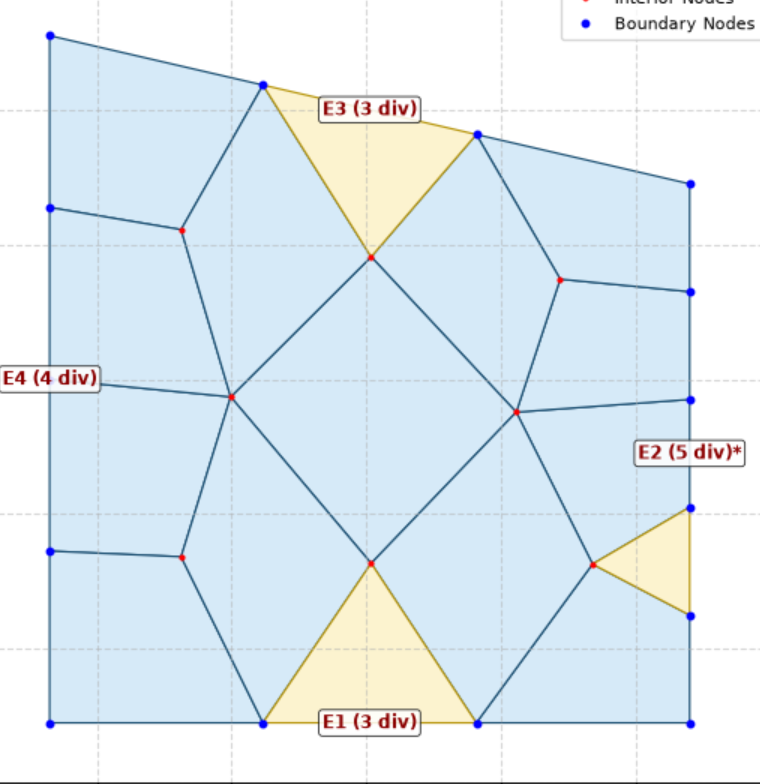
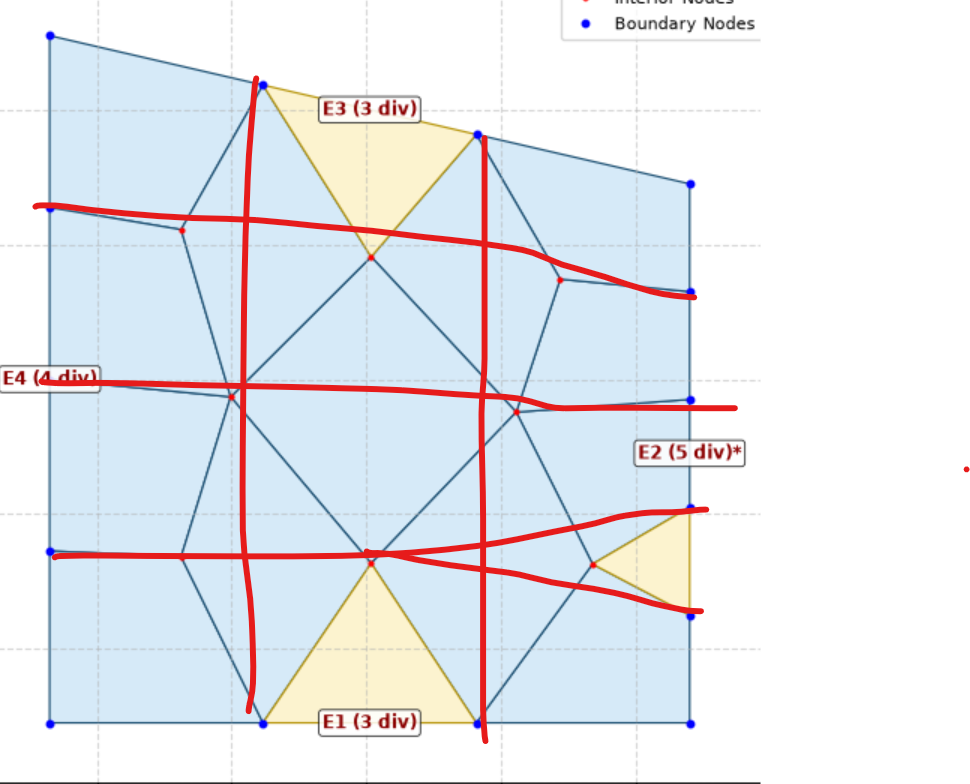

Remeshing  With  density cange  on  Edges 

In [8]:

##Block 1: Imports, Geometry & Semi-Structured Transition Grid Mesher


import tkinter as tk
from tkinter import messagebox, ttk
import matplotlib.path as mpath
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
from matplotlib.collections import PolyCollection
from matplotlib.figure import Figure
import numpy as np
from scipy.spatial import Delaunay


# =========================================================
# 1. GEOMETRY, EDGE DIVISIONS & TRANSITION QUAD MESHER
# =========================================================
def ensure_ccw(vertices):
    x, y = vertices[:, 0], vertices[:, 1]
    signed_area = 0.5 * np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y)
    return vertices[::-1] if signed_area < 0 else vertices


def compute_edge_divisions(vertices, h_boundary, edge_div_overrides):
    """Returns the exact number of subdivisions for every polygon edge."""
    num_edges = len(vertices)
    divs = []
    for i in range(num_edges):
        if i in edge_div_overrides and edge_div_overrides[i] is not None:
            n_div = max(1, int(edge_div_overrides[i]))
        else:
            edge_len = np.linalg.norm(
                vertices[(i + 1) % num_edges] - vertices[i]
            )
            n_div = max(1, int(np.round(edge_len / h_boundary)))
        divs.append(n_div)
    return divs


def try_semi_structured_quad_mesh(raw_vertices, edge_divs):
    """Builds a structured or single-axis transition quad-dominant mesh for any 4-sided polygon:
      - Case A (n1 == n3 and n2 == n4): Pure mapped Q4 grid (0 T3 triangles).
      - Case B (n1 == n3 and n2 != n4, or n2 == n4 and n1 != n3):
        Mapped grid along the matching axis + row-by-row transition on the differing axis,
        achieving the mathematical minimum |n_a - n_b| triangles (e.g., 1 T3 for 4 vs 5).
    Returns (nodes, q4_els, t3_els, num_boundary_nodes) or None if both pairs differ.
    """
    vertices = ensure_ccw(np.asarray(raw_vertices, dtype=float))
    if len(vertices) != 4:
        return None

    n1, n2, n3, n4 = edge_divs

    if n1 == n3:
        rot = 0
    elif n2 == n4:
        rot = 1
    else:
        return None

    verts = np.roll(vertices, -rot, axis=0)
    divs = list(np.roll(edge_divs, -rot))
    nu = divs[0]
    nv_right = divs[1]
    nv_left = divs[3]

    v0, v1, v2, v3 = verts[0], verts[1], verts[2], verts[3]

    boundary_nodes = []
    b_e1, b_e2, b_e3, b_e4 = [], [], [], []

    for i in range(nu):
        u = i / nu
        b_e1.append(len(boundary_nodes))
        boundary_nodes.append((1.0 - u) * v0 + u * v1)

    for j in range(nv_right):
        v = j / nv_right
        b_e2.append(len(boundary_nodes))
        boundary_nodes.append((1.0 - v) * v1 + v * v2)

    for k in range(nu):
        i = nu - k
        u = i / nu
        b_e3.append(len(boundary_nodes))
        boundary_nodes.append((1.0 - u) * v3 + u * v2)

    for k in range(nv_left):
        j = nv_left - k
        v = j / nv_left
        b_e4.append(len(boundary_nodes))
        boundary_nodes.append((1.0 - v) * v0 + v * v3)

    num_b = len(boundary_nodes)
    interior_nodes = []

    def add_interior(pt):
        idx = num_b + len(interior_nodes)
        interior_nodes.append(pt)
        return idx

    col_chains = []

    left_chain = [b_e1[0]] + b_e4[::-1]
    col_chains.append(left_chain)

    for i in range(1, nu):
        u = i / nu
        chain = [b_e1[i]]
        for j in range(1, nv_left):
            v = j / nv_left
            pt = (
                (1.0 - u) * (1.0 - v) * v0
                + u * (1.0 - v) * v1
                + u * v * v2
                + (1.0 - u) * v * v3
            )
            chain.append(add_interior(pt))
        chain.append(b_e3[nu - i])
        col_chains.append(chain)

    right_chain = [b_e2[0]] + b_e2[1:] + [b_e3[0]]
    col_chains.append(right_chain)

    q4_els = []
    t3_els = []

    for i in range(nu - 1):
        cL, cR = col_chains[i], col_chains[i + 1]
        for j in range(nv_left):
            q4_els.append([cL[j], cR[j], cR[j + 1], cL[j + 1]])

    cL = col_chains[nu - 1]
    cR = col_chains[nu]

    if nv_left == nv_right:
        for j in range(nv_left):
            q4_els.append([cL[j], cR[j], cR[j + 1], cL[j + 1]])
    else:
        pL, pR = 0, 0
        while pL < nv_left or pR < nv_right:
            remL = nv_left - pL
            remR = nv_right - pR
            if remL > 0 and remR > 0:
                if remL == remR:
                    q4_els.append([cL[pL], cR[pR], cR[pR + 1], cL[pL + 1]])
                    pL += 1
                    pR += 1
                elif remR > remL:
                    t3_els.append([cL[pL], cR[pR], cR[pR + 1]])
                    pR += 1
                else:
                    t3_els.append([cL[pL], cR[pR], cL[pL + 1]])
                    pL += 1
            elif remR > 0:
                t3_els.append([cL[pL], cR[pR], cR[pR + 1]])
                pR += 1
            else:
                t3_els.append([cL[pL], cR[pR], cL[pL + 1]])
                pL += 1

    nodes = (
        np.vstack([boundary_nodes, interior_nodes])
        if interior_nodes
        else np.array(boundary_nodes)
    )
    return nodes, q4_els, t3_els, num_b


##Block 2: Unstructured Fallback Mesher, Smoothing & Quad Converters

# =========================================================
# 2. UNSTRUCTURED BASE T3 & HYBRID / PURE Q4 CONVERTERS
# =========================================================
def build_base_t3_edge_control(
    raw_vertices,
    h_boundary,
    h_interior,
    edge_div_overrides,
    use_smoothing,
    iterations,
):
    """Seeds boundary edges by exact division counts and interior uniformly by h_interior."""
    vertices = ensure_ccw(np.asarray(raw_vertices, dtype=float))
    num_edges = len(vertices)
    edge_divs = compute_edge_divisions(
        vertices, h_boundary, edge_div_overrides
    )

    boundary_nodes = []
    for i in range(num_edges):
        p_start = vertices[i]
        p_end = vertices[(i + 1) % num_edges]
        n_div = edge_divs[i]
        for k in range(n_div):
            t = k / n_div
            boundary_nodes.append((1.0 - t) * p_start + t * p_end)
    boundary_nodes = np.array(boundary_nodes)

    poly_path = mpath.Path(vertices)
    xmin, ymin = vertices.min(axis=0)
    xmax, ymax = vertices.max(axis=0)
    dy = h_interior * np.sqrt(3) / 2.0

    interior_nodes = []
    row = 0
    y = ymin + dy
    while y < ymax:
        x_shift = (h_interior / 2.0) if (row % 2 == 1) else 0.0
        x = xmin + (h_interior / 2.0) + x_shift
        while x < xmax:
            pt = np.array([x, y])
            if poly_path.contains_point(pt):
                dist_to_b = np.min(
                    np.linalg.norm(boundary_nodes - pt, axis=1)
                )
                if dist_to_b > 0.50 * h_interior:
                    interior_nodes.append(pt)
            x += h_interior
        y += dy
        row += 1

    nodes = (
        np.vstack([boundary_nodes, np.array(interior_nodes)])
        if len(interior_nodes) > 0
        else boundary_nodes
    )
    num_b = len(boundary_nodes)

    tri = Delaunay(nodes)
    valid_tris = []
    for simplex in tri.simplices:
        pts = nodes[simplex]
        if poly_path.contains_point(pts.mean(axis=0)):
            area2 = (pts[1, 0] - pts[0, 0]) * (pts[2, 1] - pts[0, 1]) - (
                pts[1, 1] - pts[0, 1]
            ) * (pts[2, 0] - pts[0, 0])
            if area2 > 1e-12:
                valid_tris.append(simplex)
            elif area2 < -1e-12:
                valid_tris.append([simplex[0], simplex[2], simplex[1]])
    tris = np.array(valid_tris, dtype=int)

    if use_smoothing and len(interior_nodes) > 0 and len(tris) > 0:
        nodes = apply_laplacian_smoothing(
            nodes, tris, set(range(num_b)), iterations
        )

    return nodes, tris, num_b, edge_divs


def apply_laplacian_smoothing(nodes, elements, fixed_node_ids, iterations):
    smoothed = nodes.copy()
    neighbors = {i: set() for i in range(len(smoothed))}
    for el in elements:
        k = len(el)
        for i in range(k):
            neighbors[el[i]].update([el[(i - 1) % k], el[(i + 1) % k]])

    for _ in range(iterations):
        new_pos = smoothed.copy()
        for idx in range(len(smoothed)):
            if idx not in fixed_node_ids and neighbors[idx]:
                nbrs = list(neighbors[idx])
                new_pos[idx] = 0.5 * smoothed[idx] + 0.5 * np.mean(
                    smoothed[nbrs], axis=0
                )
        smoothed = new_pos
    return smoothed


def merge_t3_to_hybrid_q4_t3(nodes, tris):
    """Pairs T3 triangles into Q4 quads while prioritizing triangles with fewer options."""
    edge_to_tris = {}
    for t_idx, tri in enumerate(tris):
        for i in range(3):
            edge = tuple(sorted((tri[i], tri[(i + 1) % 3])))
            edge_to_tris.setdefault(edge, []).append(t_idx)

    raw_pairs = []
    tri_partner_count = {i: 0 for i in range(len(tris))}
    for edge, adj_tris in edge_to_tris.items():
        if len(adj_tris) == 2:
            t1, t2 = adj_tris
            quad = form_ccw_quad(nodes, tris[t1], tris[t2], edge)
            if quad is not None:
                quality = quad_angle_quality(nodes[quad])
                if quality > 0.25:
                    raw_pairs.append((quality, t1, t2, quad))
                    tri_partner_count[t1] += 1
                    tri_partner_count[t2] += 1

    scored_pairs = []
    for quality, t1, t2, quad in raw_pairs:
        min_options = min(tri_partner_count[t1], tri_partner_count[t2])
        priority = (1 if min_options == 1 else 0, quality)
        scored_pairs.append((priority, t1, t2, quad))

    scored_pairs.sort(key=lambda x: x[0], reverse=True)

    used_tris = set()
    q4_elements = []
    for _, t1, t2, quad in scored_pairs:
        if t1 not in used_tris and t2 not in used_tris:
            q4_elements.append(quad)
            used_tris.add(t1)
            used_tris.add(t2)

    t3_elements = [
        list(tris[i]) for i in range(len(tris)) if i not in used_tris
    ]
    return nodes, q4_elements, t3_elements


def form_ccw_quad(nodes, tri1, tri2, shared_edge):
    u, v = shared_edge
    opp1 = [n for n in tri1 if n not in shared_edge][0]
    opp2 = [n for n in tri2 if n not in shared_edge][0]
    quad = [u, opp1, v, opp2]
    pts = nodes[quad]

    crosses = []
    for i in range(4):
        v1 = pts[(i + 1) % 4] - pts[i]
        v2 = pts[(i + 2) % 4] - pts[(i + 1) % 4]
        crosses.append(v1[0] * v2[1] - v1[1] * v2[0])

    if all(c > 1e-12 for c in crosses):
        return quad
    if all(c < -1e-12 for c in crosses):
        return quad[::-1]
    return None


def quad_angle_quality(pts):
    max_dev = 0.0
    for k in range(4):
        v1 = pts[(k - 1) % 4] - pts[k]
        v2 = pts[(k + 1) % 4] - pts[k]
        cos_t = np.clip(
            np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2)),
            -1.0,
            1.0,
        )
        max_dev = max(max_dev, abs(90.0 - np.degrees(np.arccos(cos_t))))
    return max(0.0, 1.0 - max_dev / 90.0)


def subdivide_t3_to_pure_q4(nodes, tris, num_boundary_nodes):
    new_nodes = list(nodes)
    edge_midpoints = {}
    q4_elements = []
    boundary_midpoints = set()

    edge_counts = {}
    for tri in tris:
        for i in range(3):
            edge = tuple(sorted((tri[i], tri[(i + 1) % 3])))
            edge_counts[edge] = edge_counts.get(edge, 0) + 1

    def get_midpoint(u, v):
        edge = tuple(sorted((u, v)))
        if edge not in edge_midpoints:
            mid_pt = 0.5 * (nodes[u] + nodes[v])
            mid_idx = len(new_nodes)
            new_nodes.append(mid_pt)
            edge_midpoints[edge] = mid_idx
            if edge_counts[edge] == 1:
                boundary_midpoints.add(mid_idx)
        return edge_midpoints[edge]

    for n0, n1, n2 in tris:
        m01 = get_midpoint(n0, n1)
        m12 = get_midpoint(n1, n2)
        m20 = get_midpoint(n2, n0)
        c_idx = len(new_nodes)
        new_nodes.append((nodes[n0] + nodes[n1] + nodes[n2]) / 3.0)
        q4_elements.append([n0, m01, c_idx, m20])
        q4_elements.append([n1, m12, c_idx, m01])
        q4_elements.append([n2, m20, c_idx, m12])

    fixed_ids = set(range(num_boundary_nodes)) | boundary_midpoints
    return np.array(new_nodes), q4_elements, fixed_ids



## Block 3: Tkinter GUI Class Setup & Interactive Polygon Controls

# =========================================================
# 3. INTERACTIVE TKINTER REMESHING APPLICATION
# =========================================================
class PerEdgeDivisionRemesherApp:
    def __init__(self, root):
        self.root = root
        self.root.title('Interactive Remesher: Transition Q4 & Per-Edge Divisions')
        self.root.geometry('1050x720')

        self.clicked_pts = []
        self.polygon_closed = False
        self.edge_overrides = {}
        self.current_edge_divs = []

        # --- Left Sidebar ---
        panel = ttk.Frame(root, padding=14)
        panel.pack(side=tk.LEFT, fill=tk.Y)

        # 1. Element Type
        ttk.Label(
            panel, text='1. Element Type', font=('Arial', 11, 'bold')
        ).pack(anchor=tk.W, pady=(0, 4))
        self.mode_var = tk.StringVar(value='HYBRID')
        for label, val in [
            ('Hybrid / Transition Quad (Q4 + T3)', 'HYBRID'),
            ('Pure All-Quad (Q4 Only)', 'PURE_Q4'),
            ('Triangle (T3 Only)', 'T3'),
        ]:
            ttk.Radiobutton(
                panel,
                text=label,
                variable=self.mode_var,
                value=val,
                command=self.remesh,
            ).pack(anchor=tk.W)

        ttk.Separator(panel, orient=tk.HORIZONTAL).pack(fill=tk.X, pady=6)

        # 2. Polygon Drawing
        ttk.Label(
            panel, text='2. Draw Polygon', font=('Arial', 11, 'bold')
        ).pack(anchor=tk.W, pady=(2, 4))
        ttk.Label(
            panel,
            text='• Left-Click: Add corners\n• Right-Click: Close & Mesh',
            justify=tk.LEFT,
        ).pack(anchor=tk.W, pady=(0, 6))

        btn_row = ttk.Frame(panel)
        btn_row.pack(fill=tk.X, pady=(0, 8))
        ttk.Button(
            btn_row, text='Close & Mesh', command=self.close_and_mesh
        ).pack(side=tk.LEFT, expand=True, fill=tk.X, padx=(0, 3))
        ttk.Button(
            btn_row, text='Clear All', command=self.clear_canvas
        ).pack(side=tk.RIGHT, expand=True, fill=tk.X, padx=(3, 0))

        ttk.Separator(panel, orient=tk.HORIZONTAL).pack(fill=tk.X, pady=6)

        # 3. Boundary & Per-Edge Divisions
        ttk.Label(
            panel, text='3. Boundary Edge Divisions', font=('Arial', 11, 'bold')
        ).pack(anchor=tk.W, pady=(2, 4))

        b_row = ttk.Frame(panel)
        b_row.pack(fill=tk.X)
        ttk.Label(b_row, text='Default Boundary (h_b):').pack(side=tk.LEFT)
        self.hb_var = tk.DoubleVar(value=0.90)
        ttk.Spinbox(
            b_row,
            from_=0.12,
            to=2.00,
            increment=0.05,
            textvariable=self.hb_var,
            width=6,
            command=self.remesh,
        ).pack(side=tk.RIGHT)

        ttk.Scale(
            panel,
            from_=0.12,
            to=1.80,
            variable=self.hb_var,
            command=self.on_slider_drag,
        ).pack(fill=tk.X, pady=(2, 8))

        # Per-Edge Subdivision Override
        ttk.Label(
            panel, text='Per-Edge Subdivision Override:', font=('Arial', 9, 'bold')
        ).pack(anchor=tk.W)
        edge_row = ttk.Frame(panel)
        edge_row.pack(fill=tk.X, pady=(2, 4))
        self.edge_select = ttk.Combobox(edge_row, state='readonly', width=11)
        self.edge_select.pack(side=tk.LEFT, padx=(0, 4))
        self.edge_select.bind('<<ComboboxSelected>>', self.on_edge_selected)

        ttk.Label(edge_row, text='Divs:').pack(side=tk.LEFT)
        self.edge_div_var = tk.IntVar(value=5)
        ttk.Spinbox(
            edge_row,
            from_=1,
            to=50,
            textvariable=self.edge_div_var,
            width=5,
        ).pack(side=tk.RIGHT)

        edge_btn_row = ttk.Frame(panel)
        edge_btn_row.pack(fill=tk.X, pady=(0, 8))
        ttk.Button(
            edge_btn_row, text='Apply Edge Divs', command=self.apply_edge_override
        ).pack(side=tk.LEFT, expand=True, fill=tk.X, padx=(0, 3))
        ttk.Button(
            edge_btn_row, text='Reset Overrides', command=self.reset_edge_overrides
        ).pack(side=tk.RIGHT, expand=True, fill=tk.X, padx=(3, 0))

        ttk.Separator(panel, orient=tk.HORIZONTAL).pack(fill=tk.X, pady=6)

        # 4. Unstructured Interior Mesh Density
        ttk.Label(
            panel, text='4. Unstructured Interior Density', font=('Arial', 11, 'bold')
        ).pack(anchor=tk.W, pady=(2, 4))

        i_row = ttk.Frame(panel)
        i_row.pack(fill=tk.X)
        ttk.Label(i_row, text='Interior Spacing (h_i):').pack(side=tk.LEFT)
        self.hi_var = tk.DoubleVar(value=0.90)
        ttk.Spinbox(
            i_row,
            from_=0.15,
            to=2.00,
            increment=0.05,
            textvariable=self.hi_var,
            width=6,
            command=self.remesh,
        ).pack(side=tk.RIGHT)

        ttk.Scale(
            panel,
            from_=0.15,
            to=1.80,
            variable=self.hi_var,
            command=self.on_slider_drag,
        ).pack(fill=tk.X, pady=(2, 6))

        self.smooth_var = tk.BooleanVar(value=True)
        ttk.Checkbutton(
            panel,
            text='Laplacian Smoothing (10 passes)',
            variable=self.smooth_var,
            command=self.remesh,
        ).pack(anchor=tk.W, pady=(2, 4))

        self.show_edge_labels = tk.BooleanVar(value=True)
        ttk.Checkbutton(
            panel,
            text='Show Edge Divisions on Plot',
            variable=self.show_edge_labels,
            command=self.remesh,
        ).pack(anchor=tk.W, pady=(0, 6))

        ttk.Button(panel, text='Remesh Now', command=self.remesh).pack(
            fill=tk.X, pady=(0, 6)
        )

        ttk.Separator(panel, orient=tk.HORIZONTAL).pack(fill=tk.X, pady=6)

        # 5. Summary Report
        self.stats_label = ttk.Label(
            panel,
            text='Draw a closed polygon\nto start remeshing.',
            font=('Consolas', 10),
            justify=tk.LEFT,
        )
        self.stats_label.pack(anchor=tk.W)

        # --- Right Canvas ---
        plot_frame = ttk.Frame(root, padding=10)
        plot_frame.pack(side=tk.RIGHT, fill=tk.BOTH, expand=True)

        self.fig = Figure(figsize=(6, 6), dpi=100)
        self.ax = self.fig.add_subplot(111)
        self.canvas = FigureCanvasTkAgg(self.fig, master=plot_frame)
        self.canvas.get_tk_widget().pack(fill=tk.BOTH, expand=True)
        self.canvas.mpl_connect('button_press_event', self.on_canvas_click)

        self.redraw_drawing_state()

    def setup_axes(self, title):
        self.ax.clear()
        self.ax.set_xlim(0.0, 6.0)
        self.ax.set_ylim(0.0, 6.0)
        self.ax.set_aspect('equal', adjustable='box')
        self.ax.grid(True, linestyle='--', alpha=0.5)
        self.ax.set_xlabel('X')
        self.ax.set_ylabel('Y')
        self.ax.set_title(title)

    def on_canvas_click(self, event):
        if event.inaxes != self.ax or self.polygon_closed:
            return
        if event.button == 1:
            x_snap = round(event.xdata * 20) / 20.0
            y_snap = round(event.ydata * 20) / 20.0
            self.clicked_pts.append([x_snap, y_snap])
            self.redraw_drawing_state()
        elif event.button == 3:
            self.close_and_mesh()

    def redraw_drawing_state(self):
        self.setup_axes(
            f'Left-Click Corners ({len(self.clicked_pts)} placed) | Right-Click to Mesh'
        )
        if len(self.clicked_pts) > 0:
            pts = np.array(self.clicked_pts)
            self.ax.plot(pts[:, 0], pts[:, 1], 'k-o', lw=1.5, markersize=5)
            self.ax.plot(pts[0, 0], pts[0, 1], 'go', markersize=8)
        self.canvas.draw()

    def close_and_mesh(self):
        if len(self.clicked_pts) < 3:
            messagebox.showwarning(
                'Not Enough Points', 'Click at least 3 corners first.'
            )
            return
        self.polygon_closed = True
        self.edge_overrides = {}
        ccw_pts = ensure_ccw(np.asarray(self.clicked_pts, dtype=float))
        self.clicked_pts = ccw_pts.tolist()

        edge_labels = [f'Edge {i + 1}' for i in range(len(self.clicked_pts))]
        self.edge_select['values'] = edge_labels
        self.edge_select.current(0)
        self.remesh()
        self.on_edge_selected()

    def clear_canvas(self):
        self.clicked_pts = []
        self.polygon_closed = False
        self.edge_overrides = {}
        self.current_edge_divs = []
        self.edge_select['values'] = []
        self.stats_label.config(
            text='Draw a closed polygon\nto start remeshing.'
        )
        self.redraw_drawing_state()




## Block 4: Edge Override Handlers, remesh() Method & Main Entry Guard


    def on_edge_selected(self, _event=None):
        idx = self.edge_select.current()
        if idx >= 0 and idx < len(self.current_edge_divs):
            self.edge_div_var.set(self.current_edge_divs[idx])

    def apply_edge_override(self):
        if not self.polygon_closed:
            return
        idx = self.edge_select.current()
        if idx >= 0:
            self.edge_overrides[idx] = int(self.edge_div_var.get())
            self.remesh()

    def reset_edge_overrides(self):
        self.edge_overrides = {}
        self.remesh()
        self.on_edge_selected()

    def on_slider_drag(self, _event=None):
        self.hb_var.set(round(self.hb_var.get(), 2))
        self.hi_var.set(round(self.hi_var.get(), 2))
        self.remesh()
        self.on_edge_selected()

    def remesh(self):
        if not self.polygon_closed:
            return

        hb = max(0.10, float(self.hb_var.get()))
        hi = max(0.12, float(self.hi_var.get()))
        use_smooth = self.smooth_var.get()
        mode = self.mode_var.get()

        ccw_verts = ensure_ccw(np.asarray(self.clicked_pts, dtype=float))
        edge_divs = compute_edge_divisions(ccw_verts, hb, self.edge_overrides)
        self.current_edge_divs = edge_divs

        # Use structured / semi-structured transition mesh when 4-sided and 1+ opposite pair matches
        semi_result = (
            try_semi_structured_quad_mesh(ccw_verts, edge_divs)
            if mode == 'HYBRID'
            else None
        )

        if semi_result is not None:
            nodes, q4_els, t3_els, num_b = semi_result
            if use_smooth:
                nodes = apply_laplacian_smoothing(
                    nodes, q4_els + t3_els, set(range(num_b)), 10
                )
            display_divs = edge_divs
            display_num_b = num_b
            mesh_type_tag = (
                'Mapped TFI Grid' if len(t3_els) == 0 else 'Transition Grid'
            )
        else:
            nodes, tris, num_b, edge_divs = build_base_t3_edge_control(
                self.clicked_pts,
                hb,
                hi,
                self.edge_overrides,
                use_smooth,
                iterations=10,
            )
            if mode == 'T3':
                q4_els, t3_els = [], [list(t) for t in tris]
            elif mode == 'HYBRID':
                nodes, q4_els, t3_els = merge_t3_to_hybrid_q4_t3(nodes, tris)
                if use_smooth:
                    nodes = apply_laplacian_smoothing(
                        nodes, q4_els + t3_els, set(range(num_b)), 10
                    )
            else:  # PURE_Q4
                nodes, q4_els, fixed_ids = subdivide_t3_to_pure_q4(
                    nodes, tris, num_b
                )
                t3_els = []
                if use_smooth:
                    nodes = apply_laplacian_smoothing(
                        nodes, q4_els, fixed_ids, 10
                    )

            display_divs = (
                [d * 2 for d in edge_divs] if mode == 'PURE_Q4' else edge_divs
            )
            display_num_b = num_b * 2 if mode == 'PURE_Q4' else num_b
            mesh_type_tag = 'Unstructured'

        total_els = len(q4_els) + len(t3_els)
        report = (
            f'Mesh Type:        {mesh_type_tag}\n'
            f'Default h_b:      {hb:.2f}\n'
            f'Interior h_i:     {hi:.2f}\n'
            f'-----------------------------\n'
            f'Boundary Nodes:   {display_num_b}\n'
            f'Total Nodes:      {len(nodes)}\n'
            f'Q4 Quads (Blue):  {len(q4_els)}\n'
            f'T3 Tris (Amber):  {len(t3_els)}\n'
            f'Total Elements:   {total_els}\n'
            f'Reissner-Mindlin: {len(nodes) * 3} DOFs'
        )
        self.stats_label.config(text=report)

        self.setup_axes(
            f'Remeshed ({mesh_type_tag}): {len(nodes)} Nodes ({len(q4_els)} Q4 + {len(t3_els)} T3)'
        )
        if q4_els:
            self.ax.add_collection(
                PolyCollection(
                    [nodes[el] for el in q4_els],
                    facecolors='#d6eaf8',
                    edgecolors='#1b4f72',
                    linewidths=0.85,
                )
            )
        if t3_els:
            self.ax.add_collection(
                PolyCollection(
                    [nodes[el] for el in t3_els],
                    facecolors='#fcf3cf',
                    edgecolors='#b7950b',
                    linewidths=0.85,
                )
            )

        self.ax.plot(
            nodes[num_b:, 0],
            nodes[num_b:, 1],
            'ro',
            markersize=2.0,
            label='Interior Nodes',
        )
        self.ax.plot(
            nodes[:num_b, 0],
            nodes[:num_b, 1],
            'bo',
            markersize=3.2,
            label='Boundary Nodes',
        )

        if self.show_edge_labels.get():
            pts = np.asarray(self.clicked_pts)
            n_pts = len(pts)
            for i in range(n_pts):
                mid = 0.5 * (pts[i] + pts[(i + 1) % n_pts])
                star = '*' if i in self.edge_overrides else ''
                tag = f'E{i + 1} ({display_divs[i]} div){star}'
                self.ax.text(
                    mid[0],
                    mid[1],
                    tag,
                    fontsize=8.5,
                    fontweight='bold',
                    color='darkred',
                    ha='center',
                    va='center',
                    bbox=dict(
                        boxstyle='round,pad=0.2', fc='white', alpha=0.85, lw=0.6
                    ),
                )

        self.ax.legend(loc='upper right', fontsize=8)
        self.canvas.draw()


if __name__ == '__main__':
    root = tk.Tk()
    app = PerEdgeDivisionRemesherApp(root)
    root.mainloop()

